# LVHM experiments — phase 2.1

Reinforcement learning for adaptive job sequencing in a low-volume high-mix SO-ARM101 work cell
(UTS 43008, Assignment 3, team Amazing Abundance).

Phase 2.1 of `experiments_phase2.ipynb`. Same environment, same agents, same hyperparameters.
What changed is the comparison and how it is validated.

| Change | Why |
|---|---|
| **ATCSR+C replaces plain ATCSR** in the reported set &mdash; 8 baselines, not 9 | The headline comparison is the agent against the strongest baseline, so that baseline should have the same 16 actions the agent has. Plain ATCSR stays in the code for the ablation |
| **Rolling CP-SAT** added | It is *provably optimal* on the jobs it can see. If the learned policy beats it, the gain cannot have come from optimising harder &mdash; only from anticipating arrivals it cannot see. That is the research question, isolated |
| **Known-answer experiment** | The clairvoyant ceiling is our own code. On a small instance with the randomness switched off, every order can be enumerated, so the true optimum is *known* and the ceiling can be checked against it |
| **`partc` profile** | Sized for the Part C initial-results report: enough runs for a defensible table, far short of the full study |
| **Part C report cell** | Writes the three tables the brief asks for &mdash; methods, settings, initial results &mdash; to `results/partc_report.md` |

**The eight baselines:** FCFS &middot; SPT &middot; EDF &middot; NTF &middot; LRF &middot; Random &middot; ATCSR+C &middot; Rolling CP-SAT.
Plus the clairvoyant CP-SAT ceiling, which is **not** a baseline &mdash; it sees the whole shift in
advance, so no policy could run it.

## How to run

**Amazon SageMaker (T4 GPU)**

1. Upload this file to SageMaker (JupyterLab: Upload Files).
2. Use an instance with an NVIDIA T4, for example `ml.g4dn.xlarge`, and a PyTorch kernel.
3. Leave `PROFILE = 'smoke'` in section 3 and run all cells. This takes a few minutes and checks
   every code path, including a checkpoint save/reload round trip.
4. If the smoke test passes, set `PROFILE = 'full'`, restart the kernel, and run all cells again.

**If the session expires mid-training:** reopen the notebook and run all cells again with the same
`PROFILE`. Training resumes from the last checkpoint. Nothing needs changing.

> **Where `runs/` lives matters.** Checkpoints are written under `RUN_DIR`, relative to this
> notebook. On SageMaker Studio, `/home/sagemaker-user` survives a kernel restart and an idle
> shutdown, but **not** deletion of the space. If the run matters, point `RUN_DIR` at a persistent
> location or copy `runs/` to S3 between sections — there is a commented hook for this in section 9.

**Locally:** `uv sync --extra notebook`, then
`uv run --extra notebook --with jupyterlab jupyter lab notebooks/experiments_phase2.ipynb`, and skip
the pip cell.

## 1. Install packages

In [2]:
# Packages this notebook needs.
#
# READ THIS FIRST if you have a CUDA build of PyTorch installed.
# stable-baselines3 >= 2.9 requires torch >= 2.8. If your installed torch is older, pip will
# UPGRADE it -- and the default PyPI wheel on Windows is CPU-ONLY, so a working CUDA install
# gets silently replaced. The cell below reports what you have before changing anything.
#
# Losing CUDA is not a disaster here: the network is only ~26,000 parameters, so CUDA is about
# 1.8x faster than CPU (measured: 8.7 ms vs 15.8 ms per gradient update). The whole partc run
# is roughly 19 min on GPU against 24 min on CPU. If you want CUDA back, install a matching
# CUDA build from the PyTorch index FIRST, then re-run this cell:
#     pip install torch --index-url https://download.pytorch.org/whl/cu124 --upgrade
# (pick the cu-version for your driver at pytorch.org, and make sure it is >= 2.8)

import importlib.util, importlib.metadata as _md

_before = None
if importlib.util.find_spec('torch') is not None:
    try:
        import torch as _t
        _before = (_t.__version__, _t.cuda.is_available())
        print(f'torch already present: {_before[0]}   CUDA available: {_before[1]}')
        if _before[1] and tuple(int(x) for x in _t.__version__.split('.')[:2]) < (2, 8):
            print('  !! Your torch is older than 2.8, so installing stable-baselines3 WILL replace')
            print('     it with a CPU-only build. Install a CUDA torch >= 2.8 first if you care.')
    except Exception as exc:
        print('torch is installed but will not import:', exc)
        print('  If you just ran an install, RESTART THE KERNEL - the DLLs were being swapped.')
else:
    print('torch not installed; it will be pulled in as a dependency (CPU-only on Windows)')

%pip install -q gymnasium sb3-contrib pandas matplotlib ortools scipy

print()
print('If torch changed version just now, RESTART THE KERNEL before running anything else.')

torch already present: 2.14.0+cpu   CUDA available: False
Note: you may need to restart the kernel to use updated packages.

If torch changed version just now, RESTART THE KERNEL before running anything else.


D:\MyNameIsSid\UTS\Notes And Lectures\Reinforcement Learning\lvhm\.venv\Scripts\python.exe: No module named pip


## 2. Imports and device

In [3]:
import json
import os
import shutil
import time
from dataclasses import dataclass, replace, asdict
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from gymnasium import spaces
from sb3_contrib import MaskablePPO
from sb3_contrib.common.maskable.policies import MaskableActorCriticPolicy
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv
from torch import nn

# Optional dependencies, each guarded so the notebook still runs without them.
try:
    from ortools.sat.python import cp_model
    HAVE_ORTOOLS = True
except ImportError:
    HAVE_ORTOOLS = False
    print('ortools not available - section 13 (CP-SAT bound) will be skipped')

try:
    from scipy import stats as scipy_stats
    HAVE_SCIPY = True
except ImportError:
    HAVE_SCIPY = False
    print('scipy not available - the Wilcoxon test in section 16 will be skipped')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

device: cpu 


## 3. Profile: smoke or full

`PROFILE` is the only thing to change between a check run and the real run.

- **`smoke`** — one seed, a couple of thousand steps, a handful of shifts. Exercises every code path
  including checkpoint save and reload. A few minutes. The point is to fail fast and cheaply.
- **`full`** — the real run. Roughly the Part B budget.

Everything else in this notebook reads from `CFG`, so nothing else needs editing.

In [4]:
# PROFILE = 'smoke'   # 'smoke' -> check the code  
PROFILE = 'partc' # 'partc' -> initial-results report
# PROFILE = 'full' # 'full' -> the study

PROFILES = {
    'smoke': dict(
        seeds=[0],
        ppo_timesteps=3_000, dqn_timesteps=3_000,
        dqn_learning_starts=256,  # MUST be < dqn_timesteps or no gradient update ever runs
        val_every=1_500, n_val_shifts=3, n_test_shifts=5,
        atcsr_grid=2,            # K values per axis in the tuning grid
        n_bound_shifts=2,        # shifts given a CP-SAT bound
        bound_time_limit=10.0,   # seconds per shift
        bound_max_jobs=12,       # truncate so CP-SAT can prove optimality quickly
        rolling_time_limit=0.05,
        ckpt_every=1_000,
    ),
    'partc': dict(
        # Sized for the Part C *initial* results report, deliberately short.
        #
        # 100k steps is about 1,300 shifts of experience. Still well short of the full study's
        # 300k (~3,900 shifts), so the policies will NOT have fully converged - the report cell
        # states that automatically. But it is enough to show a real learning curve rather than
        # noise, and it is nearly free: measured environment throughput is ~11,000 steps/sec, so
        # 100k x 6 runs is about a minute of environment time. The run's actual cost is the
        # rolling solver (~7 min) and the CP-SAT bound (<=5 min), and neither depends on the
        # step count at all.
        seeds=[0, 1, 2],
        ppo_timesteps=100_000, dqn_timesteps=100_000,
        dqn_learning_starts=2_000,
        val_every=5_000, n_val_shifts=10, n_test_shifts=30,
        atcsr_grid=3,
        n_bound_shifts=10,
        # 30 s was NOT enough: on the 2026-10-02 run, 0/10 shifts solved to proven optimality and
        # 3/10 returned a "clairvoyant" schedule WORSE than the best dispatch rule (two of them
        # negative). The failures were the largest shifts - 89 and 90 jobs. A 71-job shift needs
        # about 60 s for a 2%-loose bound, so the big ones need several minutes.
        bound_time_limit=300.0,
        bound_max_jobs=None,
        rolling_time_limit=0.1,   # seconds per decision for the rolling solver
        ckpt_every=10_000,
    ),
    'full': dict(
        # 10 seeds is the statistical target: about a 19% miss rate against 51% at 5 seeds.
        # Finished seeds are skipped via the manifest, and training is interleaved by seed,
        # so stopping early leaves a balanced, reportable subset. Drop to range(5) if the
        # budget printed by the smoke run says 10 will not fit before the freeze.
        seeds=list(range(10)),
        ppo_timesteps=300_000, dqn_timesteps=300_000,
        dqn_learning_starts=5_000,
        val_every=25_000, n_val_shifts=20, n_test_shifts=100,
        atcsr_grid=4,
        n_bound_shifts=20,
        bound_time_limit=60.0,
        bound_max_jobs=None,     # None: the whole shift, bound may not be proven optimal
        rolling_time_limit=0.1,
        ckpt_every=10_000,
    ),
}
CFG = PROFILES[PROFILE]

# Fail fast on a setting that would silently produce a DQN that never learns:
# with learning_starts >= timesteps the update loop is skipped entirely and the run
# still "succeeds", which is exactly the false green light the smoke test exists to prevent.
assert CFG['dqn_learning_starts'] < CFG['dqn_timesteps'], (
    f"dqn_learning_starts ({CFG['dqn_learning_starts']}) must be below "
    f"dqn_timesteps ({CFG['dqn_timesteps']}) or the DQN performs zero gradient updates")

SEEDS          = CFG['seeds']
PPO_TIMESTEPS  = CFG['ppo_timesteps']
DQN_TIMESTEPS  = CFG['dqn_timesteps']
VAL_EVERY      = CFG['val_every']
N_VAL_SHIFTS   = CFG['n_val_shifts']
N_TEST_SHIFTS  = CFG['n_test_shifts']
CKPT_EVERY     = CFG['ckpt_every']       # environment steps between resumable checkpoints
VAL_SEED, TEST_SEED = 20_000, 10_000     # validation and test shifts never overlap

RETRAIN   = False     # True: ignore existing checkpoints and train from scratch
RESUME    = True      # True: continue from the last checkpoint if training was interrupted
SAVE_BUFFER = True    # save the DQN replay buffer so a resume is faithful (see section 9 for size)

RUN_DIR     = Path('runs') / PROFILE       # checkpoints, kept separate per profile
RESULTS_DIR = Path('results') / PROFILE    # tables and figures
RUN_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ROLLING_TIME_LIMIT = CFG['rolling_time_limit']

print(f'PROFILE={PROFILE}  seeds={SEEDS}  steps={PPO_TIMESTEPS}  test shifts={N_TEST_SHIFTS}')
print(f'runs -> {RUN_DIR.resolve()}')
print(f'results -> {RESULTS_DIR.resolve()}')

PROFILE=partc  seeds=[0, 1, 2]  steps=100000  test shifts=30
runs -> D:\MyNameIsSid\UTS\Notes And Lectures\Reinforcement Learning\lvhm\notebooks\runs\partc
results -> D:\MyNameIsSid\UTS\Notes And Lectures\Reinforcement Learning\lvhm\notebooks\results\partc


## 4. Products and environment settings

Unchanged from phase 1. Time is in seconds and one shift is 480 s. A product is only its weight and
fragility; processing time follows from those two. The product table that used to be displayed here
now runs in the smoke test.

In [5]:
# Products: (weight in kg, fragility from 0 to 1). The agent never sees the product name.
PRODUCTS = {
    'P1': (0.03, 0.10),  # light, robust
    'P2': (0.08, 0.60),  # light, fragile
    'P3': (0.18, 0.20),  # heavy, robust
    'P4': (0.05, 0.85),  # light, very fragile
    'P5': (0.12, 0.45),  # never trained on, inside the training range
    'P6': (0.23, 0.95),  # never trained on, outside the training range
}
PRODUCT_NAMES = tuple(PRODUCTS)
FAMILIAR = ('P1', 'P2', 'P3', 'P4')

# Penalty weights on test shifts: alpha per late second, beta per switch second, delta per drop
EVAL_WEIGHTS = (0.015, 0.15, 0.6)


@dataclass(frozen=True)
class EnvConfig:
    # Shift: jobs arrive as a Poisson process
    shift_length: float = 480.0
    arrival_rate: float = 0.14                # jobs per second on test shifts (0.28 = busy day)
    arrival_rate_range: tuple = (0.07, 0.21)  # training draws a rate per episode
    initial_jobs: int = 3                     # backlog waiting at the start of the shift
    slack: tuple = (5.0, 50.0)                # deadline = arrival + processing + slack

    # SO-ARM101 timing measured in MuJoCo; one station per tray, the arm stays at the last station
    num_trays: int = 2
    travel_time: float = 1.15                 # extra swing when switching station
    empty_time: float = 1.388                 # swing to the tray, descend, close the gripper
    loaded_time_base: float = 0.929           # loaded motion = base + per_slowdown * slowdown
    loaded_time_per_slowdown: float = 0.987

    # Handling speed: slowdown = 1 + 1.5 * weight / 0.25 + 1.5 * fragility
    slow_weight: float = 1.5
    slow_fragility: float = 1.5

    # Noise and drops
    proc_noise_sigma: float = 0.10            # log-normal noise on each attempt
    drop_base: float = 0.01
    drop_fragility: float = 0.20
    drop_weight: float = 0.05
    drop_max: float = 0.5
    drop_time_fraction: float = 0.5           # share of the processing time lost on a drop
    max_attempts: int = 2                     # the second drop scraps the job

    # Careful pick mode
    careful_mode: bool = True
    careful_drop_factor: float = 0.3
    careful_slowdown: float = 1.5

    # Fixed reward terms
    on_time_bonus: float = 1.0
    unfinished_penalty: float = 1.0

    # Observation: the 8 oldest waiting jobs and these scales
    num_slots: int = 8
    proc_scale: float = 8.0
    weight_scale: float = 0.25
    deadline_scale: float = 60.0
    wait_scale: float = 120.0
    max_queue_obs: int = 32

    # Training ranges: features (weight, fragility) and penalty weights (alpha, beta, delta)
    feature_low: tuple = (0.02, 0.0)
    feature_high: tuple = (0.20, 0.9)
    weight_low: tuple = (0.005, 0.05, 0.2)
    weight_high: tuple = (0.03, 0.30, 1.5)
    holdout_radius: float = 0.1               # box around P5 (normalised features) that training never samples

    def slowdown(self, weight, fragility):
        return 1.0 + self.slow_weight * np.asarray(weight) / self.weight_scale + self.slow_fragility * np.asarray(fragility)

    def proc_time(self, weight, fragility, careful=False):
        # Nominal time of one pick-and-place, before noise
        slow = self.slowdown(weight, fragility) * (self.careful_slowdown if careful else 1.0)
        return self.empty_time + self.loaded_time_base + self.loaded_time_per_slowdown * slow

    def drop_probability(self, weight, fragility, careful=False):
        q = self.drop_base + self.drop_fragility * np.asarray(fragility) + self.drop_weight * np.asarray(weight) / self.weight_scale
        q = np.minimum(q, self.drop_max)
        return q * self.careful_drop_factor if careful else q


ENV = EnvConfig()

## 5. Shift instances

A shift instance draws everything random about one shift up front: arrivals, deadlines, processing noise and the random number behind every possible drop. Every policy evaluated on the same instance therefore faces the same jobs and the same drop outcome for the same pick (common random numbers).

Training samples weight and fragility continuously, but never near P5, so P5 is truly unseen.

In [6]:
@dataclass(frozen=True)
class ShiftInstance:
    arrival: np.ndarray    # arrival time of each job, ascending
    proc: np.ndarray       # nominal processing time in normal mode
    weight: np.ndarray
    fragility: np.ndarray
    tray: np.ndarray       # source tray, 0 or 1
    deadline: np.ndarray
    noise: np.ndarray      # processing-time noise per job and attempt
    u_drop: np.ndarray     # uniform draw per job and attempt; the pick drops if it is below the drop probability

    def __len__(self):
        return len(self.arrival)


def normalise_features(cfg, feats):
    low, high = np.array(cfg.feature_low), np.array(cfg.feature_high)
    return (np.asarray(feats, dtype=float) - low) / (high - low)


def in_holdout(cfg, feats):
    # True inside the box around P5 that training never samples
    p5 = normalise_features(cfg, PRODUCTS['P5'])
    return np.abs(normalise_features(cfg, feats) - p5).max(axis=-1) < cfg.holdout_radius


def sample_training_features(cfg, rng, n):
    # Uniform (weight, fragility); anything that lands near P5 is drawn again
    low, high = np.array(cfg.feature_low), np.array(cfg.feature_high)
    feats = rng.uniform(low, high, size=(n, 2))
    reject = in_holdout(cfg, feats)
    while reject.any():
        feats[reject] = rng.uniform(low, high, size=(int(reject.sum()), 2))
        reject = in_holdout(cfg, feats)
    return feats


def sample_instance(cfg, rng, products=None, arrival_rate=None):
    # products=None: continuous training features; otherwise each job is one of the named products
    rate = cfg.arrival_rate if arrival_rate is None else arrival_rate
    n_arrivals = rng.poisson(rate * cfg.shift_length)
    arrival = np.concatenate([np.zeros(cfg.initial_jobs), np.sort(rng.uniform(0.0, cfg.shift_length, n_arrivals))])
    n = len(arrival)
    if products is None:
        feats = sample_training_features(cfg, rng, n)
    else:
        product = np.array([PRODUCT_NAMES.index(p) for p in products])[rng.integers(len(products), size=n)]
        feats = np.array([PRODUCTS[PRODUCT_NAMES[i]] for i in product]).reshape(n, 2)
    weight, fragility = feats[:, 0], feats[:, 1]
    proc = cfg.proc_time(weight, fragility)
    attempts = (n, cfg.max_attempts)
    return ShiftInstance(
        arrival=arrival,
        proc=proc,
        weight=weight,
        fragility=fragility,
        tray=rng.integers(cfg.num_trays, size=n),
        deadline=arrival + proc + rng.uniform(*cfg.slack, size=n),
        noise=np.exp(rng.normal(0.0, cfg.proc_noise_sigma, size=attempts)),
        u_drop=rng.uniform(size=attempts),
    )


def make_instances(cfg, products, n, seed):
    # A fixed, reproducible set of shifts
    return [sample_instance(cfg, np.random.default_rng([seed, i]), products) for i in range(n)]


# Check the hold-out: training never samples near P5, and P6 lies outside the training range
assert not in_holdout(ENV, sample_training_features(ENV, np.random.default_rng(0), 100_000)).any()
assert in_holdout(ENV, PRODUCTS['P5'])
assert np.any((np.array(PRODUCTS['P6']) < ENV.feature_low) | (np.array(PRODUCTS['P6']) > ENV.feature_high))

## 6. The environment

A discrete-event Gymnasium environment. A decision happens whenever the arm is idle and jobs are waiting; one step simulates the whole pick-and-place.

- **Observation (79 values):** the 8 oldest waiting jobs (present, processing time, weight, fragility, time to deadline, tray, waiting time, dropped once) and global features (shift remaining, arm station, queue length, penalty weights).
- **Action (16):** `a % 8` is the job slot, `a >= 8` means careful mode. Empty slots are masked.
- **Reward:** +1 per job finished on time, minus alpha per late second (charged as lateness accrues for every waiting job), minus beta per switch second, minus delta per drop, minus 1 per job still waiting at the end of the shift.
- The penalty weights are sampled per training episode and shown to the agent, so they can change at test time without retraining.

In [7]:
class LVHMSchedulingEnv(gym.Env):
    def __init__(self, config=None):
        super().__init__()
        self.cfg = cfg = config or EnvConfig()
        self.num_modes = 2 if cfg.careful_mode else 1
        # per slot: present, proc, weight, fragility, time to deadline, tray one-hot, waiting, dropped once
        self.slot_dim = 7 + cfg.num_trays
        # global: shift remaining, arm station one-hot, queue length, penalty weights
        self.global_dim = 1 + cfg.num_trays + 1 + 3
        self.action_space = spaces.Discrete(cfg.num_slots * self.num_modes)

        slot_low = np.zeros(self.slot_dim, dtype=np.float32)
        slot_low[4] = -1.0  # time to deadline is negative once a job is late
        global_high = np.ones(self.global_dim, dtype=np.float32)
        global_high[1 + cfg.num_trays] = cfg.max_queue_obs / cfg.num_slots
        global_high[-3:] = 2.0  # test-time weights may exceed the training range
        low = np.concatenate([np.tile(slot_low, cfg.num_slots), np.zeros(self.global_dim, dtype=np.float32)])
        high = np.concatenate([np.ones(self.slot_dim * cfg.num_slots, dtype=np.float32), global_high])
        self.observation_space = spaces.Box(low, high, dtype=np.float32)
        self._inst = None

    def reset(self, *, seed=None, options=None):
        # options: instance (a fixed shift), products, arrival_rate, weights (alpha, beta, delta)
        super().reset(seed=seed)
        options = options or {}
        cfg = self.cfg
        inst = options.get('instance')
        if inst is None:
            rate = options.get('arrival_rate')
            if rate is None and cfg.arrival_rate_range is not None:
                rate = self.np_random.uniform(*cfg.arrival_rate_range)
            inst = sample_instance(cfg, self.np_random, options.get('products'), rate)
        weights = options.get('weights')
        if weights is None:
            weights = self.np_random.uniform(cfg.weight_low, cfg.weight_high)

        self._inst = inst
        self._w = np.asarray(weights, dtype=float)
        self._attempts = np.zeros(len(inst), dtype=int)
        self._queue = []   # waiting job indices, in arrival order
        self._next = 0     # index of the next job to arrive
        self._t = 0.0
        self._arm = 0      # station the arm is at
        self._stats = {k: 0 for k in ('decisions', 'completed', 'on_time', 'late', 'drops', 'scrapped', 'unfinished', 'careful')}
        self._stats.update(tardiness=0.0, travel=0.0, score=0.0)

        self._admit(self._t)
        if not self._queue:
            self._t = float(inst.arrival[self._next])
            self._admit(self._t)
        return self._obs(), {'t': self._t}

    def step(self, action):
        cfg, inst = self.cfg, self._inst
        alpha, beta, delta = self._w
        if not self.action_masks()[action]:
            raise ValueError(f'action {action} selects an empty slot')
        slot, careful = int(action) % cfg.num_slots, int(action) // cfg.num_slots == 1
        j = self._queue[slot]

        # Simulate the pick: a station switch if needed, then the pick-and-place or a drop
        t0 = self._t
        travel = cfg.travel_time if inst.tray[j] != self._arm else 0.0
        attempt = self._attempts[j]
        proc = cfg.proc_time(inst.weight[j], inst.fragility[j], careful) * inst.noise[j, attempt]
        dropped = bool(inst.u_drop[j, attempt] < cfg.drop_probability(inst.weight[j], inst.fragility[j], careful))
        t1 = t0 + travel + (cfg.drop_time_fraction * proc if dropped else proc)

        # Lateness accrued during [t0, t1] by every job in the system, including jobs that arrived meanwhile
        self._admit(t1)
        deadlines = inst.deadline[self._queue]
        late = float(np.maximum(0.0, t1 - np.maximum(t0, deadlines)).sum())

        reward = -alpha * late - beta * travel
        self._arm = int(inst.tray[j])
        if dropped:
            self._attempts[j] += 1
            self._stats['drops'] += 1
            reward -= delta
            if self._attempts[j] >= cfg.max_attempts:  # second drop: scrap the job
                self._queue.remove(j)
                self._stats['scrapped'] += 1
        else:
            self._queue.remove(j)
            self._stats['completed'] += 1
            if t1 <= inst.deadline[j]:
                self._stats['on_time'] += 1
                reward += cfg.on_time_bonus
            else:
                self._stats['late'] += 1

        self._t = t1
        terminated = self._advance()
        if terminated:
            self._stats['unfinished'] = len(self._queue)
            reward -= cfg.unfinished_penalty * len(self._queue)

        self._stats['decisions'] += 1
        self._stats['careful'] += careful
        self._stats['tardiness'] += late
        self._stats['travel'] += travel
        self._stats['score'] += reward

        info = {'t': self._t, 'job': j, 'slot': slot, 'careful': careful, 'start': t0, 'end': t1, 'travel': travel, 'dropped': dropped}
        if terminated:
            info['episode_metrics'] = dict(self._stats)
        return self._obs(), float(reward), terminated, False, info

    def action_masks(self):
        # Valid actions (MaskablePPO looks for this method): occupied slots, in both modes
        slots = np.zeros(self.cfg.num_slots, dtype=bool)
        slots[: min(len(self._queue), self.cfg.num_slots)] = True
        return np.tile(slots, self.num_modes)

    def _admit(self, t):
        # Jobs that have arrived by time t join the queue
        while self._next < len(self._inst) and self._inst.arrival[self._next] <= t:
            self._queue.append(self._next)
            self._next += 1

    def _advance(self):
        # Move the clock to the next decision point; True when the shift is over
        if self._t >= self.cfg.shift_length:
            return True
        if self._queue:
            return False
        if self._next >= len(self._inst) or self._inst.arrival[self._next] >= self.cfg.shift_length:
            return True
        self._t = float(self._inst.arrival[self._next])
        self._admit(self._t)
        return False

    def _obs(self):
        cfg, inst, t = self.cfg, self._inst, self._t
        vis = np.array(self._queue[: cfg.num_slots], dtype=int)
        n = len(vis)
        slots = np.zeros((cfg.num_slots, self.slot_dim), dtype=np.float32)
        slots[:n, 0] = 1.0                                                                # present
        slots[:n, 1] = np.minimum(inst.proc[vis] / cfg.proc_scale, 1.0)                   # processing time
        slots[:n, 2] = np.minimum(inst.weight[vis] / cfg.weight_scale, 1.0)               # weight
        slots[:n, 3] = inst.fragility[vis]                                                # fragility
        slots[:n, 4] = np.clip((inst.deadline[vis] - t) / cfg.deadline_scale, -1.0, 1.0)  # time to deadline
        slots[np.arange(n), 5 + inst.tray[vis]] = 1.0                                     # tray one-hot
        slots[:n, 5 + cfg.num_trays] = np.minimum((t - inst.arrival[vis]) / cfg.wait_scale, 1.0)  # waiting time
        slots[:n, 6 + cfg.num_trays] = self._attempts[vis] > 0                            # dropped once

        w_low, w_high = np.array(cfg.weight_low), np.array(cfg.weight_high)
        glob = np.concatenate(
            [
                [max(0.0, (cfg.shift_length - t) / cfg.shift_length)],           # shift remaining
                np.eye(cfg.num_trays)[self._arm],                                # arm station
                [min(len(self._queue), cfg.max_queue_obs) / cfg.num_slots],      # queue length
                np.clip((self._w - w_low) / (w_high - w_low), 0.0, 2.0),         # penalty weights
            ]
        ).astype(np.float32)
        return np.concatenate([slots.ravel(), glob])

## 5. Rule-based baselines

The six rules from phase 1, unchanged, so the numbers stay comparable. Each sees the same 8 jobs as
the agent, picks in normal mode, and breaks ties by earliest arrival.

In [8]:
def rule(key):
    # A policy that serves the visible job with the smallest key; policies take (obs, env) and return an action
    def policy(obs, env):
        vis = np.array(env._queue[: env.cfg.num_slots], dtype=int)
        return int(np.argmin(key(env._inst, vis, env)))

    return policy


fcfs = rule(lambda inst, vis, env: inst.arrival[vis])                          # first come, first served
spt = rule(lambda inst, vis, env: inst.proc[vis])                              # shortest processing time
lrf = rule(lambda inst, vis, env: inst.fragility[vis])                         # lowest failure risk first
edf = rule(lambda inst, vis, env: inst.deadline[vis])                          # earliest deadline first
ntf = rule(lambda inst, vis, env: (inst.tray[vis] != env._arm).astype(float))  # nearest tray first


class RandomPolicy:
    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)

    def __call__(self, obs, env):
        valid = np.flatnonzero(env.action_masks()[: env.cfg.num_slots])
        return int(self.rng.choice(valid))


def rule_baselines(seed=0):
    return {'FCFS': fcfs, 'SPT': spt, 'LRF': lrf, 'EDF': edf, 'NTF': ntf, 'Random': RandomPolicy(seed)}

## 6. ATCSR, and giving rules a careful/normal decision

### ATCSR

Apparent Tardiness Cost with Setups and Ready times. A composite priority index rather than a
single-attribute sort, and the standard strong heuristic for the problem this environment actually
poses — single resource, weighted tardiness, sequence-dependent setups. Lineage: ATC
(Vepsalainen & Morton 1987), ATCS (Lee, Bhaskaran & Pinedo 1997), then the ready-time extension for
dynamic arrivals.

For each waiting job the index multiplies three factors:

$$I_j = \frac{w_j}{p_j}\;\underbrace{\exp\!\left(-\frac{\max(0,\, d_j - p_j - t)}{K_1 \bar p}\right)}_{\text{urgency}}\;\underbrace{\exp\!\left(-\frac{s_j}{K_2 \bar s}\right)}_{\text{setup}}\;\underbrace{\exp\!\left(-\frac{\max(0,\, r_j - t)}{K_3 \bar p}\right)}_{\text{ready}}$$

The job with the **highest** index is served. Reading the parts: `w/p` is the weighted-shortest-
processing-time instinct; the urgency factor rises as a deadline approaches; the setup factor
penalises a job that needs a tray switch; the ready factor discounts jobs that have not arrived yet.

Two honest notes to carry into the report:

- **`w_j = 1` for every job.** The reward charges the same tardiness rate for all jobs, so there is
  no per-job weight to use. The index is therefore ATCS-with-unit-weights, not the general form.
- **The ready-time factor is inert here.** The action space only offers jobs already in the queue, so
  `r_j <= t` always and that factor is always 1. ATCSR reduces to ATCS in this environment. It is
  implemented in full anyway, so the rule is the real one and the claim in the report is accurate.
  Say this rather than letting a marker find it.

`K1`, `K2`, `K3` are look-ahead parameters. They are **tuned on the validation shifts** in section 8 —
never on the test shifts. Comparing a tuned learned policy against an untuned heuristic is the most
common way this kind of comparison is rigged, and tuning the baseline is what makes beating it mean
something.

### Careful-aware rules

Phase 1's rules always picked in normal mode while the learned policies could choose careful
handling, which makes the changed-penalty test hard to defend. These wrappers give a rule the same
choice, using an explicit expected-cost comparison rather than a learned one:

> pick careful when `delta * (q_normal - q_careful)  >  alpha * (p_careful - p_normal) * jobs_in_system`

The left side is the expected damage cost avoided. The right side is the extra lateness the slower
motion inflicts on everything waiting. Both sides use the penalty weights the environment is
currently running, which the rule reads from the environment exactly as the learned policy reads them
from its observation.

In [9]:
def atcsr_index(inst, vis, env, K1=2.0, K2=1.0, K3=1.0):
    """ATCSR priority index for the visible jobs. Higher is more urgent."""
    cfg = env.cfg
    t = env._t
    p = inst.proc[vis]                                                   # nominal processing time
    d = inst.deadline[vis]
    s = np.where(inst.tray[vis] != env._arm, cfg.travel_time, 0.0)       # setup if a tray switch
    r = inst.arrival[vis]                                                # always <= t here
    w = np.ones(len(vis))                                                # uniform tardiness weight

    p_bar = max(float(p.mean()), 1e-9)
    s_bar = float(s.mean())

    urgency = np.exp(-np.maximum(0.0, d - p - t) / (K1 * p_bar))
    # If no visible job needs a switch, s_bar is 0 and the setup factor is inert.
    setup = np.exp(-s / (K2 * s_bar)) if s_bar > 1e-9 else np.ones(len(vis))
    ready = np.exp(-np.maximum(0.0, r - t) / (K3 * p_bar))
    return (w / p) * urgency * setup * ready


def index_policy(index_fn, **kw):
    """Wrap a priority index into a policy that serves the highest-scoring visible job."""
    def policy(obs, env):
        vis = np.array(env._queue[: env.cfg.num_slots], dtype=int)
        return int(np.argmax(index_fn(env._inst, vis, env, **kw)))
    return policy


def atcsr(K1=2.0, K2=1.0, K3=1.0):
    return index_policy(atcsr_index, K1=K1, K2=K2, K3=K3)


def careful_aware(policy):
    """Let a rule choose careful mode when the damage it avoids outweighs the lateness it adds."""
    def wrapped(obs, env):
        cfg = env.cfg
        slot = int(policy(obs, env)) % cfg.num_slots       # the job the rule wants, normal mode
        if not cfg.careful_mode:
            return slot
        j = env._queue[slot]
        w, f = env._inst.weight[j], env._inst.fragility[j]
        alpha, _beta, delta = env._w

        q_n = float(cfg.drop_probability(w, f, careful=False))
        q_c = float(cfg.drop_probability(w, f, careful=True))
        p_n = float(cfg.proc_time(w, f, careful=False))
        p_c = float(cfg.proc_time(w, f, careful=True))

        damage_saved = delta * (q_n - q_c)
        lateness_added = alpha * (p_c - p_n) * max(1, len(env._queue))
        careful = damage_saved > lateness_added
        return slot + (cfg.num_slots if careful else 0)
    return wrapped


def rule_baselines_phase21(seed=0, K=(2.0, 1.0, 1.0), rolling=None):
    """The eight phase 2.1 baselines.

    ATCSR+C REPLACES plain ATCSR rather than sitting beside it: the headline comparison is the
    agent against the strongest baseline, so that baseline should have the same 16 actions the
    agent has. Plain ATCSR and EDF+C stay available below for the ablation, but are not reported.
    """
    base = rule_baselines(seed)                    # FCFS, SPT, LRF, EDF, NTF, Random
    base['ATCSR+C'] = careful_aware(atcsr(*K))     # composite index + careful/normal decision
    if rolling is not None:
        base['RollCP'] = rolling                   # solver picks the job, wrapper picks the mode
    return base


def ablation_baselines(K=(2.0, 1.0, 1.0)):
    """Not reported by default. Answers 'what did careful mode buy the rule?' in one table."""
    return {'ATCSR': atcsr(*K), 'EDF+C': careful_aware(edf)}

## 7. Evaluation helpers

`evaluate` runs a policy on fixed shifts with fixed penalty weights. `decompose_score` rebuilds the
score from its five components, which is both a readable breakdown for the report and an exact
identity the smoke test asserts on.

In [10]:
METRICS = ['on_time', 'tardiness', 'travel', 'drops', 'scrapped', 'unfinished', 'careful', 'score']


def run_episode(env, policy, instance, weights=EVAL_WEIGHTS):
    obs, _ = env.reset(options={'instance': instance, 'weights': weights})
    while True:
        obs, _, terminated, truncated, info = env.step(policy(obs, env))
        if terminated or truncated:
            return info['episode_metrics']


def evaluate(policy, instances, cfg=ENV, weights=EVAL_WEIGHTS):
    env = LVHMSchedulingEnv(cfg)
    return [run_episode(env, policy, inst, weights) for inst in instances]


def mean_metrics(results):
    return {m: float(np.mean([r[m] for r in results])) for m in METRICS}


def decompose_score(metrics, weights=EVAL_WEIGHTS, cfg=ENV):
    """Split a score into its five contributions. Sums exactly to `score`."""
    alpha, beta, delta = weights
    parts = {
        'on_time_bonus': cfg.on_time_bonus * metrics['on_time'],
        'tardiness_cost': -alpha * metrics['tardiness'],
        'travel_cost': -beta * metrics['travel'],
        'damage_cost': -delta * metrics['drops'],
        'unfinished_cost': -cfg.unfinished_penalty * metrics['unfinished'],
    }
    parts['total'] = sum(parts.values())
    return parts

In [11]:
class Validator:
    """Scores a policy on the validation shifts, keeps the best checkpoint, logs the curve.

    Phase 2 change: the curve is reloaded on resume so an interrupted run does not lose its history,
    and `best` is restored so a worse post-resume checkpoint cannot overwrite a better one.
    """

    def __init__(self, out_dir):
        self.instances = make_instances(ENV, FAMILIAR, N_VAL_SHIFTS, VAL_SEED)
        self.out_dir = Path(out_dir)
        self.csv = self.out_dir / 'validation.csv'
        self.best = -np.inf
        self.rows = []
        if self.csv.exists():                       # resuming: recover history and best score
            prev = pd.read_csv(self.csv)
            self.rows = prev.to_dict('records')
            if len(prev):
                self.best = float(prev['score'].max())
                print(f'  validator resumed: {len(prev)} points, best {self.best:.2f}')

    def __call__(self, policy, timesteps, save_best):
        row = {'timesteps': timesteps} | mean_metrics(evaluate(policy, self.instances))
        # A resumed run reloads its history, so validating again at a timestep already in the log
        # would leave two rows for that step and break every reader of the curve. Replace, append.
        self.rows = [r for r in self.rows if r['timesteps'] != timesteps]
        self.rows.append(row)
        improved = row['score'] > self.best
        if improved:
            self.best = row['score']
            save_best()
        pd.DataFrame(self.rows).to_csv(self.csv, index=False)
        print(f'  step {timesteps:>7}  validation score {row["score"]:>8.2f}'
              f'{"  <- best" if improved else ""}')

## 8. Checkpointing and resume

Phase 1 saved only the best-scoring model, which cannot resume training: the optimizer state, the
step counter and the replay buffer were all lost. Phase 2 writes two different things.

| File | Contents | Used for |
|---|---|---|
| `best_model.*` | Weights only, at the best validation score | Evaluation |
| `last_ckpt.*` | Weights **plus** optimizer state, step count, RNG state, and optionally the replay buffer | Resuming an interrupted run |
| `manifest.json` | Which seeds finished, for which algorithm, at what step | Skipping completed work |

Three details that matter when a session can die at any moment:

- **Writes are atomic.** Each file is written to `*.tmp` and then renamed. A rename is atomic on
  POSIX, so an interrupted save leaves the previous checkpoint intact rather than a truncated file.
- **The replay buffer is saved** when `SAVE_BUFFER` is on. Resuming a 100k-transition off-policy
  agent with an empty buffer restarts the hard part of learning. Cost: roughly
  `buffer_size x obs_dim x 4 bytes x 2`, about **65 MB** at the full profile. Set `SAVE_BUFFER = False`
  if disk is short and accept a slightly wrong resume.
- **Epsilon is recomputed from the step count**, not stored, so it cannot drift out of sync.

In [12]:
def atomic_save(save_fn, path):
    """Write via a temporary file and rename, so an interrupted save cannot corrupt the checkpoint."""
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    save_fn(tmp)
    # On Windows the rename can be refused for a moment while another process (usually the
    # antivirus scanner) still holds the file just written, so retry briefly before giving up.
    for attempt in range(20):
        try:
            os.replace(tmp, path)  # atomic on the same filesystem
            return
        except PermissionError:
            if attempt == 19:
                raise
            time.sleep(0.25)


MANIFEST = RUN_DIR / 'manifest.json'


def manifest_read():
    if MANIFEST.exists():
        try:
            return json.loads(MANIFEST.read_text())
        except json.JSONDecodeError:
            print('manifest unreadable, starting a fresh one')
    return {}


def manifest_write(algo, seed, **fields):
    m = manifest_read()
    m.setdefault(algo, {})[str(seed)] = fields
    atomic_save(lambda p: Path(p).write_text(json.dumps(m, indent=2)), MANIFEST)


def manifest_done(algo, seed, target_steps):
    """True when this seed already trained to at least the target step count."""
    entry = manifest_read().get(algo, {}).get(str(seed))
    return bool(entry) and entry.get('steps', 0) >= target_steps and entry.get('finished', False)


def run_dir_for(algo, seed):
    d = RUN_DIR / algo / f'seed{seed}'
    d.mkdir(parents=True, exist_ok=True)
    return d


# --- Optional: copy checkpoints to S3 between sections so they survive space deletion.
# Uncomment and set your bucket. Needs the SageMaker execution role to have s3:PutObject.
#
# S3_PREFIX = 's3://your-bucket/lvhm-runs'
# def sync_runs_to_s3():
#     os.system(f'aws s3 sync {RUN_DIR} {S3_PREFIX}/{PROFILE} --only-show-errors')
# def sync_runs_from_s3():
#     os.system(f'aws s3 sync {S3_PREFIX}/{PROFILE} {RUN_DIR} --only-show-errors')
# sync_runs_from_s3()

print('checkpoint dir:', RUN_DIR.resolve())
print('manifest:', manifest_read() or '(empty)')

checkpoint dir: D:\MyNameIsSid\UTS\Notes And Lectures\Reinforcement Learning\lvhm\notebooks\runs\partc
manifest: {'ppo': {'0': {'steps': 100352, 'finished': True, 'best_validation_score': 44.28812715354079}, '1': {'steps': 100352, 'finished': True, 'best_validation_score': 44.039609148421235}, '2': {'steps': 100352, 'finished': True, 'best_validation_score': 44.89383826467892}}, 'dqn': {'0': {'steps': 100000, 'finished': True, 'best_validation_score': 54.21125604532242}, '1': {'steps': 100000, 'finished': True, 'best_validation_score': 53.33695458568345}, '2': {'steps': 100000, 'finished': True, 'best_validation_score': 54.22371438616341}}}


## 9. Tune ATCSR on the validation shifts

A grid search over `K1`, `K2`, `K3` on the **validation** shifts. Never the test shifts — tuning on
test would inflate ATCSR the same way it would inflate the learned policies, and the point of this
baseline is to be a fair, strong opponent.

The result is written to `results/atcsr_tuning.csv`, so the report can show that the baseline was
tuned and by how much it improved. That table is worth including: it is the evidence that the
comparison is honest.

In [13]:
def tune_atcsr(grid_n=4, seed=0):
    """Grid-search ATCSR's look-ahead parameters on the validation shifts."""
    val = make_instances(ENV, FAMILIAR, N_VAL_SHIFTS, VAL_SEED)
    if grid_n <= 2:
        axis = [1.0, 3.0]
    else:
        axis = list(np.round(np.geomspace(0.5, 8.0, grid_n), 3))

    rows = []
    for K1 in axis:
        for K2 in axis:
            # K3 multiplies an always-inert factor here (every queued job has arrived),
            # so it is pinned rather than searched. Kept in the signature for correctness.
            K3 = 1.0
            m = mean_metrics(evaluate(atcsr(K1, K2, K3), val))
            rows.append({'K1': K1, 'K2': K2, 'K3': K3, **m})

    tuning = pd.DataFrame(rows).sort_values('score', ascending=False).reset_index(drop=True)
    tuning.to_csv(RESULTS_DIR / 'atcsr_tuning.csv', index=False)
    best = tuning.iloc[0]
    K = (float(best['K1']), float(best['K2']), float(best['K3']))
    print(f'ATCSR tuned on {N_VAL_SHIFTS} validation shifts over {len(rows)} settings')
    print(f'  best K1={K[0]}, K2={K[1]}, K3={K[2]}  validation score {best["score"]:.2f}')
    print(f'  worst setting scored {tuning.iloc[-1]["score"]:.2f} - the spread is why tuning matters')
    return K, tuning


ATCSR_K, atcsr_tuning = tune_atcsr(CFG['atcsr_grid'])
POLICIES_RULES = rule_baselines_phase21(K=ATCSR_K)  # RollCP is attached in section 13, once the solver exists
print('rule baselines:', list(POLICIES_RULES))

ATCSR tuned on 10 validation shifts over 9 settings
  best K1=8.0, K2=2.0, K3=1.0  validation score 51.20
  worst setting scored 44.25 - the spread is why tuning matters
rule baselines: ['FCFS', 'SPT', 'LRF', 'EDF', 'NTF', 'Random', 'ATCSR+C']


## 10. Networks shared by PPO and DQN

Unchanged from phase 1.

In [14]:
@dataclass(frozen=True)
class ObsLayout:
    num_slots: int
    slot_dim: int
    global_dim: int
    num_modes: int

    @property
    def num_actions(self):
        return self.num_slots * self.num_modes


def layout_of(env):
    return ObsLayout(env.cfg.num_slots, env.slot_dim, env.global_dim, env.num_modes)


def mlp(sizes):
    # Linear layers with ReLU in between (none after the last one)
    layers = []
    for i, (a, b) in enumerate(zip(sizes, sizes[1:])):
        layers.append(nn.Linear(a, b))
        if i < len(sizes) - 2:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)


class QueueEncoder(nn.Module):
    def __init__(self, layout, hidden=64):
        super().__init__()
        self.layout = layout
        self.job = nn.Sequential(mlp([layout.slot_dim + layout.global_dim, hidden, hidden]), nn.ReLU())
        self.context_dim = 2 * hidden

    def forward(self, obs):
        # returns job embeddings (batch, K, hidden), queue context (batch, 2 * hidden), global features
        k, s = self.layout.num_slots, self.layout.slot_dim
        slots = obs[:, : k * s].reshape(-1, k, s)
        glob = obs[:, k * s :]
        present = slots[..., 0] > 0.5
        h = self.job(torch.cat([slots, glob.unsqueeze(1).expand(-1, k, -1)], dim=-1))
        mask = present.unsqueeze(-1)
        mean = (h * mask).sum(1) / mask.sum(1).clamp(min=1)
        mx = h.masked_fill(~mask, float('-inf')).max(1).values
        mx = torch.where(present.any(1, keepdim=True), mx, torch.zeros_like(mx))  # empty queue: zeros
        return h, torch.cat([mean, mx], dim=-1), glob


class JobScorer(nn.Module):
    # One score per (job slot, pick mode), laid out as action = mode * K + slot
    def __init__(self, layout, embed_dim, context_dim, hidden=64):
        super().__init__()
        self.layout = layout
        self.net = mlp([embed_dim + context_dim, hidden, layout.num_modes])

    def forward(self, h, context):
        k = self.layout.num_slots
        scores = self.net(torch.cat([h, context.unsqueeze(1).expand(-1, k, -1)], dim=-1))  # (batch, K, modes)
        return scores.transpose(1, 2).reshape(h.shape[0], -1)


class ValueHead(nn.Module):
    def __init__(self, context_dim, global_dim, hidden=64):
        super().__init__()
        self.net = mlp([context_dim + global_dim, hidden, 1])

    def forward(self, context, glob):
        return self.net(torch.cat([context, glob], dim=-1))

## 11. Masked PPO

Unchanged except for resume. `MaskablePPO.load` restores the policy, the optimizer and
`num_timesteps`, so `learn(remaining, reset_num_timesteps=False)` continues rather than restarting.

In [15]:
PPO_PARAMS = dict(
    learning_rate=3e-4,
    n_steps=256,      # rollout length per env; 8 envs give 2048 transitions per update
    batch_size=256,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    ent_coef=0.01,    # entropy bonus, the exploration knob (DQN uses epsilon instead)
)


class JobScoringExtractor(nn.Module):
    # Fills SB3's mlp_extractor slot: latent_pi is already the action logits, latent_vf a queue embedding
    def __init__(self, layout, hidden):
        super().__init__()
        self.encoder = QueueEncoder(layout, hidden)
        self.scorer = JobScorer(layout, hidden, self.encoder.context_dim, hidden)
        self.value = nn.Sequential(mlp([self.encoder.context_dim + layout.global_dim, hidden, hidden]), nn.ReLU())
        self.latent_dim_pi = layout.num_actions
        self.latent_dim_vf = hidden

    def forward(self, features):
        h, context, glob = self.encoder(features)
        return self.scorer(h, context), self.value(torch.cat([context, glob], dim=-1))

    def forward_actor(self, features):
        h, context, _ = self.encoder(features)
        return self.scorer(h, context)

    def forward_critic(self, features):
        _, context, glob = self.encoder(features)
        return self.value(torch.cat([context, glob], dim=-1))


class JobScoringPolicy(MaskableActorCriticPolicy):
    def __init__(self, *args, layout, hidden=64, **kwargs):
        self.layout, self.hidden = layout, hidden
        super().__init__(*args, **kwargs)

    def _build_mlp_extractor(self):
        self.mlp_extractor = JobScoringExtractor(self.layout, self.hidden)

    def _build(self, lr_schedule):
        super()._build(lr_schedule)
        # The scorer already outputs logits: drop SB3's extra action layer and start the logits small
        self.action_net = nn.Identity()
        nn.init.orthogonal_(self.mlp_extractor.scorer.net[-1].weight, gain=0.01)
        nn.init.zeros_(self.mlp_extractor.scorer.net[-1].bias)
        self.optimizer = self.optimizer_class(self.parameters(), lr=lr_schedule(1), **self.optimizer_kwargs)

    def _get_constructor_parameters(self):
        return super()._get_constructor_parameters() | {'layout': self.layout, 'hidden': self.hidden}


def ppo_policy(model):
    # Deterministic masked policy for evaluation
    def policy(obs, env):
        action, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        return int(action)

    return policy

The validation callback also writes the resumable checkpoint, so an interrupted
run loses at most `CKPT_EVERY` steps of progress. Defined before the trainer that uses it.

In [16]:
class ValidationCallback(BaseCallback):
    """Validate every VAL_EVERY steps; write a resumable checkpoint every CKPT_EVERY steps."""

    def __init__(self, validator, out_dir):
        super().__init__()
        self.validator = validator
        self.out_dir = Path(out_dir)
        self.next_eval = 0
        self.next_ckpt = 0

    def _on_step(self):
        if self.num_timesteps >= self.next_eval:
            self.next_eval = self.num_timesteps + VAL_EVERY
            self._validate()
        if self.num_timesteps >= self.next_ckpt:
            self.next_ckpt = self.num_timesteps + CKPT_EVERY
            atomic_save(lambda p: self.model.save(p), self.out_dir / 'last_ckpt.zip')
        return True

    def _on_training_end(self):
        self._validate()

    def _validate(self):
        save = lambda: atomic_save(lambda p: self.model.save(p), self.out_dir / 'best_model.zip')
        self.validator(ppo_policy(self.model), self.num_timesteps, save)

And the trainer itself.

In [17]:
def train_ppo(seed, timesteps, out_dir, device=DEVICE, n_envs=8, hidden=64):
    """Train masked PPO, resuming from last_ckpt.zip when one exists."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    last = out_dir / 'last_ckpt.zip'

    venv = make_vec_env(LVHMSchedulingEnv, n_envs, seed=seed, env_kwargs={'config': ENV},
                        vec_env_cls=DummyVecEnv)
    layout = layout_of(LVHMSchedulingEnv(ENV))
    validator = Validator(out_dir)

    done_steps = 0
    if last.exists() and RESUME and not RETRAIN:
        model = MaskablePPO.load(last, env=venv, device=device)
        done_steps = int(model.num_timesteps)
        print(f'  resumed PPO from {done_steps} steps')
    else:
        model = MaskablePPO(JobScoringPolicy, venv,
                            policy_kwargs={'layout': layout, 'hidden': hidden},
                            seed=seed, device=device, **PPO_PARAMS)

    remaining = max(0, timesteps - done_steps)
    start = time.perf_counter()
    if remaining:
        model.learn(remaining, callback=ValidationCallback(validator, out_dir),
                    reset_num_timesteps=False)
    atomic_save(lambda p: model.save(p), last)
    manifest_write('ppo', seed, steps=int(model.num_timesteps), finished=True,
                   best_validation_score=float(validator.best))
    return {'seed': seed, 'device': str(model.device),
            'minutes': round((time.perf_counter() - start) / 60, 1),
            'steps': int(model.num_timesteps),
            'best_validation_score': validator.best}


def load_ppo(path):
    # Evaluation runs one shift at a time, which is faster on the CPU
    return ppo_policy(MaskablePPO.load(path, device='cpu'))

## 12. Masked double dueling DQN

Unchanged except for resume. The checkpoint carries the online and target weights, the optimizer
state, the step count, the numpy RNG state, and the replay buffer when `SAVE_BUFFER` is on. Epsilon
is recomputed from the step count rather than stored, so it cannot drift.

In [18]:
@dataclass
class DQNConfig:
    timesteps: int = DQN_TIMESTEPS
    n_envs: int = 8
    lr: float = 1e-4
    gamma: float = 0.99
    batch_size: int = 128
    buffer_size: int = 100_000
    learning_starts: int = 5_000
    train_freq: int = 4           # environment steps per gradient update
    tau: float = 0.005            # soft update rate of the target network
    eps_start: float = 1.0
    eps_end: float = 0.05
    eps_fraction: float = 0.3     # share of training over which epsilon decays
    warmup_edf_steps: int = 0     # optionally act with EDF first to seed the replay buffer
    hidden: int = 64
    grad_clip: float = 10.0
    device: str = DEVICE


class DuelingJobQNet(nn.Module):
    def __init__(self, layout, hidden=64):
        super().__init__()
        self.encoder = QueueEncoder(layout, hidden)
        self.advantage = JobScorer(layout, hidden, self.encoder.context_dim, hidden)
        self.value = ValueHead(self.encoder.context_dim, layout.global_dim, hidden)

    def forward(self, obs, mask):
        h, context, glob = self.encoder(obs)
        adv = self.advantage(h, context)
        adv_mean = (adv * mask).sum(1, keepdim=True) / mask.sum(1, keepdim=True).clamp(min=1)
        q = self.value(context, glob) + adv - adv_mean
        return q.masked_fill(~mask, -1e9)


class ReplayBuffer:
    def __init__(self, capacity, obs_dim, num_actions):
        self.capacity, self.size, self.pos = capacity, 0, 0
        self.obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.mask = np.zeros((capacity, num_actions), dtype=bool)
        self.next_mask = np.zeros((capacity, num_actions), dtype=bool)
        self.action = np.zeros(capacity, dtype=np.int64)
        self.reward = np.zeros(capacity, dtype=np.float32)
        self.done = np.zeros(capacity, dtype=np.float32)

    def add(self, obs, mask, action, reward, next_obs, next_mask, done):
        i = self.pos
        self.obs[i], self.mask[i], self.action[i], self.reward[i] = obs, mask, action, reward
        self.next_obs[i], self.next_mask[i], self.done[i] = next_obs, next_mask, done
        self.pos = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, rng, batch_size, device):
        idx = rng.integers(self.size, size=batch_size)
        names = ('obs', 'mask', 'action', 'reward', 'next_obs', 'next_mask', 'done')
        return {name: torch.as_tensor(getattr(self, name)[idx], device=device) for name in names}


def dqn_policy(net):
    # Greedy masked policy for evaluation
    device = next(net.parameters()).device

    def policy(obs, env):
        with torch.no_grad():
            q = net(torch.as_tensor(obs[None], device=device), torch.as_tensor(env.action_masks()[None], device=device))
        return int(q.argmax(1))

    return policy


def dqn_update(online, target, optimizer, batch, cfg):
    q = online(batch['obs'], batch['mask']).gather(1, batch['action'][:, None]).squeeze(1)
    with torch.no_grad():
        best_next = online(batch['next_obs'], batch['next_mask']).argmax(1, keepdim=True)  # online net picks
        next_q = target(batch['next_obs'], batch['next_mask']).gather(1, best_next).squeeze(1)  # target net scores
        done = batch['done'].bool()
        next_q = torch.where(done, torch.zeros_like(next_q), next_q)  # no future after the shift ends
        y = batch['reward'] + cfg.gamma * next_q
    loss = F.smooth_l1_loss(q, y)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), cfg.grad_clip)
    optimizer.step()
    with torch.no_grad():
        for p, tp in zip(online.parameters(), target.parameters()):
            tp.lerp_(p, cfg.tau)


def dqn_save_ckpt(path, online, target, optimizer, buffer, step, rng):
    blob = {
        'online': online.state_dict(),
        'target': target.state_dict(),
        'optimizer': optimizer.state_dict(),
        'step': int(step),
        'rng': rng.bit_generator.state,
        'torch_rng': torch.get_rng_state(),
        'has_buffer': bool(SAVE_BUFFER),
    }
    if SAVE_BUFFER:
        blob['buffer'] = {
            'size': buffer.size, 'pos': buffer.pos,
            'obs': buffer.obs[: buffer.size], 'next_obs': buffer.next_obs[: buffer.size],
            'mask': buffer.mask[: buffer.size], 'next_mask': buffer.next_mask[: buffer.size],
            'action': buffer.action[: buffer.size], 'reward': buffer.reward[: buffer.size],
            'done': buffer.done[: buffer.size],
        }
    atomic_save(lambda p: torch.save(blob, p), path)


def dqn_load_ckpt(path, online, target, optimizer, buffer, rng):
    blob = torch.load(path, map_location='cpu', weights_only=False)
    online.load_state_dict(blob['online'])
    target.load_state_dict(blob['target'])
    optimizer.load_state_dict(blob['optimizer'])
    rng.bit_generator.state = blob['rng']
    torch.set_rng_state(blob['torch_rng'].cpu() if hasattr(blob['torch_rng'], 'cpu') else blob['torch_rng'])
    if blob.get('has_buffer') and 'buffer' in blob:
        b = blob['buffer']
        n = int(b['size'])
        for name in ('obs', 'next_obs', 'mask', 'next_mask', 'action', 'reward', 'done'):
            getattr(buffer, name)[:n] = b[name]
        buffer.size, buffer.pos = n, int(b['pos'])
    return int(blob['step'])


def train_dqn(seed, cfg, out_dir):
    """Train the masked double dueling DQN, resuming from last_ckpt.pt when one exists."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    last = out_dir / 'last_ckpt.pt'

    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    device = torch.device(cfg.device)
    envs = [LVHMSchedulingEnv(ENV) for _ in range(cfg.n_envs)]
    layout = layout_of(envs[0])
    online = DuelingJobQNet(layout, cfg.hidden).to(device)
    target = DuelingJobQNet(layout, cfg.hidden).to(device)
    target.load_state_dict(online.state_dict())
    target.requires_grad_(False)
    optimizer = torch.optim.Adam(online.parameters(), lr=cfg.lr)
    buffer = ReplayBuffer(cfg.buffer_size, envs[0].observation_space.shape[0], layout.num_actions)
    validator = Validator(out_dir)

    step = 0
    if last.exists() and RESUME and not RETRAIN:
        step = dqn_load_ckpt(last, online, target, optimizer, buffer, rng)
        print(f'  resumed DQN from {step} steps, buffer holds {buffer.size}')

    def validate(s):
        save = lambda: atomic_save(lambda p: torch.save(online.state_dict(), p),
                                   out_dir / 'best_model.pt')
        validator(dqn_policy(online), s, save)

    obs = np.stack([env.reset(seed=seed * 1000 + i)[0] for i, env in enumerate(envs)])
    masks = np.stack([env.action_masks() for env in envs])
    next_val = step                      # validate immediately on resume
    next_ckpt = step + CKPT_EVERY
    updates_due = 0.0
    start = time.perf_counter()

    while step < cfg.timesteps:
        if step >= next_val:
            validate(step)
            next_val = step + VAL_EVERY
        if step >= next_ckpt:
            dqn_save_ckpt(last, online, target, optimizer, buffer, step, rng)
            next_ckpt = step + CKPT_EVERY

        eps = max(cfg.eps_end,
                  cfg.eps_start - (cfg.eps_start - cfg.eps_end) * step / (cfg.eps_fraction * cfg.timesteps))
        with torch.no_grad():
            greedy = online(torch.as_tensor(obs, device=device),
                            torch.as_tensor(masks, device=device)).argmax(1).cpu().numpy()
        for i, env in enumerate(envs):
            if step < cfg.warmup_edf_steps:
                action = edf(obs[i], env)
            elif rng.random() < eps:
                action = int(rng.choice(np.flatnonzero(masks[i])))
            else:
                action = int(greedy[i])
            next_obs, reward, terminated, truncated, _ = env.step(action)
            next_mask = env.action_masks()
            buffer.add(obs[i], masks[i], action, reward, next_obs, next_mask, float(terminated))
            if terminated or truncated:
                next_obs, _ = env.reset()
                next_mask = env.action_masks()
            obs[i], masks[i] = next_obs, next_mask
        step += cfg.n_envs

        if step < cfg.learning_starts:
            continue
        updates_due += cfg.n_envs / cfg.train_freq
        while updates_due >= 1:
            updates_due -= 1
            dqn_update(online, target, optimizer, buffer.sample(rng, cfg.batch_size, device), cfg)

    validate(step)
    dqn_save_ckpt(last, online, target, optimizer, buffer, step, rng)
    manifest_write('dqn', seed, steps=int(step), finished=True,
                   best_validation_score=float(validator.best))
    return {'seed': seed, 'device': str(device),
            'minutes': round((time.perf_counter() - start) / 60, 1),
            'steps': int(step), 'best_validation_score': validator.best}


def load_dqn(path, hidden=64):
    net = DuelingJobQNet(layout_of(LVHMSchedulingEnv(ENV)), hidden)
    net.load_state_dict(torch.load(path, map_location='cpu'))
    return dqn_policy(net.eval())

## 13. CP-SAT clairvoyant bound

### What it is

Every test shift is pre-drawn in full, so **in hindsight the shift is deterministic**. That lets a
solver be asked a question no online policy can answer: *given perfect foreknowledge of this exact
shift, what is the best possible score?* The answer is a ceiling. Every policy's score can then be
reported as a fraction of the headroom between the best rule and that ceiling, instead of as a bare
number nobody can calibrate.

This is the standard reference discipline in the scheduling literature, which reports *gap to solver*
rather than only *beat the heuristics*. "Clairvoyant" is the established name for a bound computed
with foreknowledge of a realised sample path.

### What is modelled, and what is relaxed

| Modelled exactly | Relaxed away |
|---|---|
| Arrival times, deadlines, trays | **Drops.** Every pick succeeds on its first attempt |
| Realised processing time (nominal x this shift's noise draw) | **Careful mode.** Pointless once drops are gone |
| Sequence-dependent setup (1.15 s per tray switch) | Lateness accrual detail: unfinished jobs are charged to the shift end |
| On-time bonus, tardiness, switching and unfinished penalties | — |

Removing drops makes the problem strictly easier, so **the result is an upper bound, not the true
optimum.** State it that way. The bound is loose by roughly the damage cost a real policy cannot
avoid, which the results tables let you estimate.

### Two numbers come back, and they mean different things

- **`bound`** — CP-SAT's proven ceiling (`BestObjectiveBound`). Valid even when the solve times out,
  which is why a time limit is safe here.
- **`clairvoyant`** — the best schedule CP-SAT actually constructed. An *achievable* perfect-
  foreknowledge schedule, so it is the fairer thing to compare a policy against.
- **`status`** — `OPTIMAL` means the two coincide and the bound is tight.

At the smoke profile the shift is truncated to a few jobs (`bound_max_jobs`) so CP-SAT proves
optimality in seconds and you can see the machinery works. At the full profile it runs on whole
shifts with a time limit, and may return `FEASIBLE` with a looser bound — still valid, just not tight.

### Measured on one real 71-job test shift

These were timed before shipping, so you know what to expect rather than discovering it during a run:

| `max_jobs` | Time limit | Status | Bound | Clairvoyant | Bound looseness | Actual time |
|---|---|---|---|---|---|---|
| 14 | 30 s | OPTIMAL | 13.65 | 13.65 | 0.0% | 0.1 s |
| 20 | 30 s | OPTIMAL | 19.31 | 19.31 | 0.0% | 0.2 s |
| 30 | 60 s | OPTIMAL | 28.79 | 28.79 | 0.0% | 4.3 s |
| 45 | 60 s | FEASIBLE | 42.93 | 42.76 | 0.4% | 60 s |
| **None (all 71)** | **60 s** | FEASIBLE | **69.10** | **67.72** | **2.0%** | 60 s |
| None (all 71) | 180 s | FEASIBLE | 69.28 | 67.72 | 2.3% | 180 s |

Three things follow, and they are worth knowing before you plan the run:

- **Whole shifts are affordable.** A 2%-loose bound in 60 s is good enough, so the full profile uses
  `bound_max_jobs=None`. Budget **about 20 minutes** for 20 shifts.
- **More time buys almost nothing.** Tripling the limit to 180 s did not improve the bound. If you
  need a tighter number, truncate to 30 jobs and get a *proven* optimum in seconds instead.
- **The headroom is large.** The clairvoyant schedule scored **67.7** against the best dispatch rule's
  roughly **51**. That is about **16 points** of room — so there is genuinely something for a learned
  policy to win, and the comparison will not be splitting hairs. Temper it with one caveat: this bound
  relaxes drops away, and a real policy cannot avoid roughly 5 points of damage cost, so a realistic
  ceiling is nearer **63** than 68.

In [19]:
MS = 1000          # integer milliseconds: CP-SAT needs integers
OBJ = 1_000_000    # objective units per unit of reward


def cpsat_bound(inst, cfg=ENV, weights=EVAL_WEIGHTS, time_limit=60.0, max_jobs=None, workers=8):
    """Upper bound on the score achievable on one pre-drawn shift, with perfect foreknowledge."""
    if not HAVE_ORTOOLS:
        raise RuntimeError('ortools is not installed')
    alpha, beta, delta = weights
    H = int(round(cfg.shift_length * MS))

    # Only jobs that could be started before the shift clock expires.
    idx = np.flatnonzero(inst.arrival < cfg.shift_length)
    if max_jobs is not None:
        idx = idx[:max_jobs]
    n = len(idx)
    if n == 0:
        return {'bound': 0.0, 'clairvoyant': 0.0, 'status': 'EMPTY', 'n_jobs': 0, 'seconds': 0.0}

    r = np.round(inst.arrival[idx] * MS).astype(int)
    # No-drop relaxation: every job succeeds on attempt 0, so it takes proc x noise[:, 0].
    p = np.maximum(1, np.round(inst.proc[idx] * inst.noise[idx, 0] * MS).astype(int))
    d = np.round(inst.deadline[idx] * MS).astype(int)
    tray = inst.tray[idx].astype(int)
    setup_ms = int(round(cfg.travel_time * MS))

    c_ontime = int(round(cfg.on_time_bonus * OBJ))
    c_unfin = int(round(cfg.unfinished_penalty * OBJ))
    c_tard = int(round(alpha * OBJ / MS))     # per millisecond of lateness
    c_setup = int(round(beta * OBJ / MS))     # per millisecond of switching

    m = cp_model.CpModel()
    far = H + int(p.sum()) + setup_ms * n + 1

    # Clamp: rounding an arrival just under the horizon could otherwise give an empty domain.
    r = np.minimum(r, H - 1)
    start = [m.NewIntVar(int(r[i]), H - 1, f'start{i}') for i in range(n)]
    end = [m.NewIntVar(0, far, f'end{i}') for i in range(n)]
    visit = [m.NewBoolVar(f'visit{i}') for i in range(n)]
    ivs = []
    for i in range(n):
        m.Add(end[i] == start[i] + int(p[i]))
        ivs.append(m.NewOptionalIntervalVar(start[i], int(p[i]), end[i], visit[i], f'iv{i}'))
        # Symmetry break: park unscheduled jobs at their release time.
        m.Add(start[i] == int(r[i])).OnlyEnforceIf(visit[i].Not())
    m.AddNoOverlap(ivs)

    # Sequencing with sequence-dependent setup, via a circuit over jobs plus a depot node n.
    arcs, setup_terms = [], []
    empty = m.NewBoolVar('empty')
    arcs.append((n, n, empty))
    for i in range(n):
        arcs.append((i, i, visit[i].Not()))                 # self-loop = job not scheduled
        first = m.NewBoolVar(f'first{i}')                   # depot -> i
        arcs.append((n, i, first))
        m.AddImplication(first, visit[i])
        s0 = setup_ms if tray[i] != 0 else 0                # the arm starts at station 0
        if s0:
            m.Add(start[i] >= s0).OnlyEnforceIf(first)
            setup_terms.append(s0 * first)
        last = m.NewBoolVar(f'last{i}')                     # i -> depot
        arcs.append((i, n, last))
        m.AddImplication(last, visit[i])
        for j in range(n):
            if i == j:
                continue
            lit = m.NewBoolVar(f'arc{i}_{j}')
            arcs.append((i, j, lit))
            m.AddImplication(lit, visit[i])
            m.AddImplication(lit, visit[j])
            s = setup_ms if tray[i] != tray[j] else 0
            m.Add(start[j] >= end[i] + s).OnlyEnforceIf(lit)
            if s:
                setup_terms.append(s * lit)
    m.AddCircuit(arcs)

    # Tardiness: to completion if scheduled, to the shift end if not.
    tard = []
    for i in range(n):
        t_sched = m.NewIntVar(0, far, f'ts{i}')
        m.AddMaxEquality(t_sched, [end[i] - int(d[i]), 0])
        t_i = m.NewIntVar(0, far, f'tard{i}')
        m.Add(t_i == t_sched).OnlyEnforceIf(visit[i])
        m.Add(t_i == max(0, H - int(d[i]))).OnlyEnforceIf(visit[i].Not())
        tard.append(t_i)

    # On-time is only claimed when it can be; maximisation drives it up on its own.
    ontime = []
    for i in range(n):
        o = m.NewBoolVar(f'ontime{i}')
        m.AddImplication(o, visit[i])
        m.Add(end[i] <= int(d[i])).OnlyEnforceIf(o)
        ontime.append(o)

    m.Maximize(
        c_ontime * sum(ontime)
        - c_tard * sum(tard)
        - c_setup * sum(setup_terms)
        - c_unfin * sum(1 - visit[i] for i in range(n))
    )

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = float(time_limit)
    solver.parameters.num_search_workers = int(workers)
    t0 = time.perf_counter()
    status = solver.Solve(m)
    elapsed = time.perf_counter() - t0

    name = solver.StatusName(status)
    if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return {'bound': solver.BestObjectiveBound() / OBJ,
                'clairvoyant': solver.ObjectiveValue() / OBJ,
                'status': name, 'n_jobs': int(n), 'seconds': round(elapsed, 1)}
    return {'bound': float('nan'), 'clairvoyant': float('nan'),
            'status': name, 'n_jobs': int(n), 'seconds': round(elapsed, 1)}


def bound_over_shifts(shifts, weights=EVAL_WEIGHTS, cfg=ENV, time_limit=60.0, max_jobs=None):
    rows = []
    for k, inst in enumerate(shifts):
        res = cpsat_bound(inst, cfg, weights, time_limit, max_jobs)
        rows.append({'shift': k, **res})
        print(f'  shift {k:>3}  {res["status"]:<10} bound {res["bound"]:>8.2f}  '
              f'clairvoyant {res["clairvoyant"]:>8.2f}  ({res["n_jobs"]} jobs, {res["seconds"]}s)')
    return pd.DataFrame(rows)

### Rolling CP-SAT &mdash; the strongest non-learned baseline

The clairvoyant bound above cheats: it sees the whole shift. **Rolling CP-SAT does not.** At every
decision it hands the solver only the jobs currently visible &mdash; exactly what the agent sees
&mdash; gets back the provably best order for those jobs, takes the first move, and re-solves at the
next decision.

**Why this baseline matters more than any other.** It is *optimal* on what it can see. So if a
learned policy beats it, that gain cannot have come from "optimising better" &mdash; a solver already
did that perfectly. It can only have come from **anticipating arrivals it cannot observe**, which is
the one thing reinforcement learning uniquely offers here. Without this baseline, "RL beats dispatch
rules" might only mean "optimising beats sorting", which a solver does better and with no training.

The job is chosen by the solver; the handling mode is chosen by the same expected-cost rule the other
`+C` baselines use, so it has the agent's full 16-action space and the comparison stays fair.

Measured cost: about **44 ms** per solve at 8 visible jobs, solving to proven optimality. One
evaluation pass over every condition is well under an hour.

In [20]:
ROLLING_FALLBACKS = {'n': 0, 'solved': 0}


def rolling_cpsat(time_limit=0.1, workers=1):
    """Re-solve the visible queue optimally at every decision; take the first move."""
    if not HAVE_ORTOOLS:
        raise RuntimeError('ortools is not installed')

    def policy(obs, env):
        cfg, inst = env.cfg, env._inst
        vis = env._queue[: cfg.num_slots]
        if len(vis) == 1:
            return 0
        alpha, beta, _delta = env._w
        t0 = env._t
        n = len(vis)

        # Everything relative to now, in integer milliseconds.
        p = [max(1, int(round(cfg.proc_time(inst.weight[j], inst.fragility[j]) * MS))) for j in vis]
        d = [int(round((inst.deadline[j] - t0) * MS)) for j in vis]
        tray = [int(inst.tray[j]) for j in vis]
        setup_ms = int(round(cfg.travel_time * MS))
        horizon = int(round(max(0.0, cfg.shift_length - t0) * MS)) + sum(p) + setup_ms * n + 1

        c_ontime = int(round(cfg.on_time_bonus * OBJ))
        c_tard = int(round(alpha * OBJ / MS))
        c_setup = int(round(beta * OBJ / MS))

        m = cp_model.CpModel()
        start = [m.NewIntVar(0, horizon, f's{k}') for k in range(n)]
        end = [m.NewIntVar(0, horizon, f'e{k}') for k in range(n)]
        ivs = []
        for k in range(n):
            m.Add(end[k] == start[k] + p[k])
            ivs.append(m.NewIntervalVar(start[k], p[k], end[k], f'iv{k}'))
        m.AddNoOverlap(ivs)

        # Sequence with sequence-dependent setup. Every visible job is served (no skipping):
        # the arm cannot idle, so the only question is the order.
        arcs, setup_terms, first_lits = [], [], []
        for k in range(n):
            f = m.NewBoolVar(f'first{k}')
            first_lits.append(f)
            arcs.append((n, k, f))
            s0 = setup_ms if tray[k] != env._arm else 0
            if s0:
                m.Add(start[k] >= s0).OnlyEnforceIf(f)
                setup_terms.append(s0 * f)
            arcs.append((k, n, m.NewBoolVar(f'last{k}')))
            for q in range(n):
                if k == q:
                    continue
                lit = m.NewBoolVar(f'a{k}_{q}')
                arcs.append((k, q, lit))
                sv = setup_ms if tray[k] != tray[q] else 0
                m.Add(start[q] >= end[k] + sv).OnlyEnforceIf(lit)
                if sv:
                    setup_terms.append(sv * lit)
        m.AddCircuit(arcs)

        tard, ontime = [], []
        for k in range(n):
            t = m.NewIntVar(0, horizon, f't{k}')
            m.AddMaxEquality(t, [end[k] - d[k], 0])
            tard.append(t)
            o = m.NewBoolVar(f'o{k}')
            m.Add(end[k] <= d[k]).OnlyEnforceIf(o)
            ontime.append(o)

        m.Maximize(c_ontime * sum(ontime) - c_tard * sum(tard) - c_setup * sum(setup_terms))

        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = float(time_limit)
        solver.parameters.num_search_workers = int(workers)
        status = solver.Solve(m)
        if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            # Falling back silently would quietly turn this baseline into FCFS and nobody would
            # know. Count it instead, and check the counter after evaluation.
            ROLLING_FALLBACKS['n'] += 1
            return 0
        ROLLING_FALLBACKS['solved'] += 1
        for k in range(n):
            if solver.Value(first_lits[k]):
                return k
        # No 'first' arc resolved (shouldn't happen) - take the earliest start.
        return int(min(range(n), key=lambda k: solver.Value(start[k])))

    return policy


# The solver chooses the job; the same expected-cost rule the other +C baselines use chooses
# the handling mode, so this baseline has the agent's full 16-action space.
ROLLING = careful_aware(rolling_cpsat(ROLLING_TIME_LIMIT)) if HAVE_ORTOOLS else None
if ROLLING is not None:
    POLICIES_RULES['RollCP'] = ROLLING      # completes the eight baselines
print('rolling CP-SAT baseline:', 'ready' if ROLLING else 'unavailable (ortools missing)')
print('baselines now:', list(POLICIES_RULES))
print('ROLLING_FALLBACKS counts solver timeouts; check it after evaluation, it should be 0.')

rolling CP-SAT baseline: ready
baselines now: ['FCFS', 'SPT', 'LRF', 'EDF', 'NTF', 'Random', 'ATCSR+C', 'RollCP']
ROLLING_FALLBACKS counts solver timeouts; check it after evaluation, it should be 0.


## Known-answer experiment &mdash; validating the ceiling itself

Every other number in this notebook is an **average over randomness**, so every claim is statistical.
That matters most for the ceiling: the clairvoyant bound is *our own code*, and if it has a bug the
headline "headroom captured" figure is wrong and nothing else in the project would catch it.

So: switch the randomness off. On a small instance with all jobs available at the start, no timing
noise and no drops, **every possible order can be enumerated**, which makes the true optimum *known*
rather than estimated.

Three things then have to agree:

1. brute-force enumeration of every order,
2. our CP-SAT bound,
3. every policy scoring **at or below** that optimum.

If a policy ever exceeds the optimum, something is wrong. This is a test we could not run at all
before phase 2.1.

In [21]:
import itertools


def deterministic_instance(n_jobs=7, seed=0, products=None):
    """A shift with the randomness switched off: all jobs at t=0, no noise, nothing ever drops."""
    rng = np.random.default_rng(seed)
    names = products or FAMILIAR
    feats = np.array([PRODUCTS[names[rng.integers(len(names))]] for _ in range(n_jobs)])
    weight, fragility = feats[:, 0], feats[:, 1]
    proc = ENV.proc_time(weight, fragility)
    return ShiftInstance(
        arrival=np.zeros(n_jobs),
        proc=proc, weight=weight, fragility=fragility,
        tray=rng.integers(ENV.num_trays, size=n_jobs),
        deadline=proc.cumsum() * rng.uniform(0.7, 1.4, n_jobs) + rng.uniform(5, 25, n_jobs),
        noise=np.ones((n_jobs, ENV.max_attempts)),
        u_drop=np.ones((n_jobs, ENV.max_attempts)),   # 1.0 is above every drop probability
    )


def brute_force_best(inst, cfg=ENV, weights=EVAL_WEIGHTS):
    """Exact optimum by enumerating every order. Only tractable to about 8 jobs."""
    alpha, beta, _delta = weights
    n = len(inst.arrival)
    best = -np.inf
    for perm in itertools.permutations(range(n)):
        t, arm, ok, tard, sw = 0.0, 0, 0, 0.0, 0.0
        for j in perm:
            s = cfg.travel_time if inst.tray[j] != arm else 0.0
            t += s + inst.proc[j]
            sw += s
            arm = int(inst.tray[j])
            if t <= inst.deadline[j]:
                ok += 1
            else:
                tard += t - inst.deadline[j]
        best = max(best, ok - alpha * tard - beta * sw)
    return best


def known_answer_check(n_jobs=7, n_instances=5, policies=None, verbose=True):
    """Brute force vs CP-SAT vs every policy, on instances where the answer is known."""
    rows = []
    for k in range(n_instances):
        inst = deterministic_instance(n_jobs, seed=100 + k)
        exact = brute_force_best(inst)
        row = {'instance': k, 'jobs': n_jobs, 'brute_force': round(exact, 4)}
        if HAVE_ORTOOLS:
            b = cpsat_bound(inst, ENV, EVAL_WEIGHTS, time_limit=20, max_jobs=None)
            row['cpsat'] = round(b['clairvoyant'], 4)
            row['cpsat_status'] = b['status']
            row['cpsat_matches'] = abs(b['clairvoyant'] - exact) < 1e-3
        for name, pol in (policies or {}).items():
            sc = mean_metrics(evaluate(pol, [inst]))['score']
            row[name] = round(sc, 4)
            row[name + '_ok'] = sc <= exact + 1e-6      # no policy may beat the true optimum
        rows.append(row)
    out = pd.DataFrame(rows)
    if verbose:
        cols = [c for c in out.columns if not c.endswith(('_ok', '_status'))]
        print(out[cols].to_string(index=False))
        if HAVE_ORTOOLS:
            print('\nCP-SAT reproduces the brute-force optimum on all instances:',
                  bool(out['cpsat_matches'].all()))
        viol = [c[:-3] for c in out.columns if c.endswith('_ok') and not out[c].all()]
        print('Policies exceeding the true optimum:', viol or 'none (as it must be)')
    return out

## 14. Smoke test

**Run this before any full training.** It touches every code path in the notebook at tiny scale and
asserts on the things that would silently poison a long run. It replaces phase 1's exploratory
display cells, which are now checks rather than things to look at.

What it verifies:

1. **The product table** — processing times and drop probabilities are finite and ordered sensibly.
2. **Held-out integrity** — training never samples near P5, and P6 is outside the training box.
3. **P6 is actually visible as novel** — the observation the network receives for P6 is outside the
   range it ever trained on. If a normaliser clipped it, the extrapolation test would be measuring
   nothing, so this is asserted rather than assumed.
4. **The reward identity** — score rebuilt from its five components equals the score the environment
   reported, to 6 decimal places. This is the worked example Part B asked for, as an assertion.
5. **Every baseline runs**, including ATCSR and the careful-aware variants, and the careful-aware
   ones actually use careful mode at least once.
6. **Both agents train** for a few hundred steps without error.
7. **A checkpoint round trip** — save, reload, and confirm the reloaded policy scores identically.
   This is the thing you cannot afford to discover is broken after a session expires.
8. **CP-SAT returns a valid bound**, and the bound is not below what a rule actually achieved.

If anything here fails, fix it before setting `PROFILE = 'full'`.

In [22]:
def smoke_test():
    fails = []

    def check(name, ok, detail=''):
        print(f'  {"PASS" if ok else "FAIL"}  {name}{"  " + detail if detail else ""}')
        if not ok:
            fails.append(name)

    print('1. product table')
    prod = pd.DataFrame([
        {'product': k, 'weight_kg': w, 'fragility': f,
         'processing_s': round(float(ENV.proc_time(w, f)), 2),
         'careful_s': round(float(ENV.proc_time(w, f, careful=True)), 2),
         'drop_prob': round(float(ENV.drop_probability(w, f)), 3)}
        for k, (w, f) in PRODUCTS.items()])
    print(prod.to_string(index=False))
    check('processing times finite and increasing with weight+fragility',
          bool(np.isfinite(prod['processing_s']).all())
          and prod.loc[prod['product'] == 'P1', 'processing_s'].item()
              < prod.loc[prod['product'] == 'P6', 'processing_s'].item())
    check('careful mode is slower than normal',
          bool((prod['careful_s'] > prod['processing_s']).all()))

    print('\n2. hold-out integrity')
    feats = sample_training_features(ENV, np.random.default_rng(0), 20_000)
    check('training never samples inside the P5 hole', not in_holdout(ENV, feats).any())
    check('P5 is inside the hole', bool(in_holdout(ENV, PRODUCTS['P5'])))
    p6 = np.array(PRODUCTS['P6'])
    check('P6 is outside the training box',
          bool(np.any((p6 < ENV.feature_low) | (p6 > ENV.feature_high))))
    hole = (2 * ENV.holdout_radius) ** 2
    print(f'     note: the hole is {hole:.1%} of the training box - a null result on P5 is expected,'
          ' not a success. Say so in the report.')

    print('\n3. P6 survives the observation normaliser')
    wmax, fmax = ENV.feature_high
    o_p6 = (min(ENV.proc_time(*p6) / ENV.proc_scale, 1.0), min(p6[0] / ENV.weight_scale, 1.0), p6[1])
    o_max = (min(ENV.proc_time(wmax, fmax) / ENV.proc_scale, 1.0),
             min(wmax / ENV.weight_scale, 1.0), fmax)
    check('P6 is distinguishable from the trained maximum',
          all(a > b + 1e-9 for a, b in zip(o_p6, o_max)),
          f'P6 obs {tuple(round(v, 3) for v in o_p6)} vs trained max {tuple(round(v, 3) for v in o_max)}')

    print('\n4. reward identity')
    shifts = make_instances(ENV, FAMILIAR, 3, TEST_SEED)
    mets = evaluate(edf, shifts)
    worst = 0.0
    for mt in mets:
        parts = decompose_score(mt)
        worst = max(worst, abs(parts['total'] - mt['score']))
    check('score equals the sum of its five components', worst < 1e-6, f'max error {worst:.2e}')
    print('     ' + '  '.join(f'{k}={v:.2f}' for k, v in decompose_score(mets[0]).items()))

    print('\n5. baselines')
    table = {}
    for name, pol in POLICIES_RULES.items():
        try:
            table[name] = mean_metrics(evaluate(pol, shifts))
        except Exception as exc:
            check(f'baseline {name} runs', False, repr(exc))
    print(pd.DataFrame(table).T.round(2).to_string())
    check('all baselines ran', len(table) == len(POLICIES_RULES))
    check('careful-aware rules use careful mode',
          table.get('ATCSR+C', {}).get('careful', 0) > 0 or table.get('EDF+C', {}).get('careful', 0) > 0,
          f"ATCSR+C careful picks={table.get('ATCSR+C', {}).get('careful', 0):.1f}")
    check('plain rules never use careful mode', table['EDF']['careful'] == 0)

    print('\n6-7. train a few steps, then a checkpoint round trip')
    tmp = RUN_DIR / '_smoke'
    if tmp.exists():
        shutil.rmtree(tmp)
    # The trainers record finished runs in the manifest. Give these throwaway runs their own, or
    # the 512-step smoke run overwrites seed 0's real entry and section 15 retrains it.
    global MANIFEST
    real_manifest, MANIFEST = MANIFEST, tmp / 'manifest.json'
    try:
        ppo_dir = tmp / 'ppo'
        train_ppo(0, 512, ppo_dir, n_envs=2)
        pol = load_ppo(ppo_dir / 'best_model.zip')
        a = mean_metrics(evaluate(pol, shifts))['score']
        b = mean_metrics(evaluate(load_ppo(ppo_dir / 'best_model.zip'), shifts))['score']
        check('PPO trains, saves and reloads deterministically', abs(a - b) < 1e-9, f'{a:.3f}')
        check('PPO wrote a resumable checkpoint', (ppo_dir / 'last_ckpt.zip').exists())
    except Exception as exc:
        check('PPO path', False, repr(exc))

    try:
        dqn_dir = tmp / 'dqn'
        dcfg = DQNConfig(timesteps=512, n_envs=2, learning_starts=64, buffer_size=2_000)
        train_dqn(0, dcfg, dqn_dir)
        a = mean_metrics(evaluate(load_dqn(dqn_dir / 'best_model.pt'), shifts))['score']
        b = mean_metrics(evaluate(load_dqn(dqn_dir / 'best_model.pt'), shifts))['score']
        check('DQN trains, saves and reloads deterministically', abs(a - b) < 1e-9, f'{a:.3f}')
        check('DQN wrote a resumable checkpoint', (dqn_dir / 'last_ckpt.pt').exists())
        # Resume must not restart from zero.
        net = DuelingJobQNet(layout_of(LVHMSchedulingEnv(ENV)), 64)
        tgt = DuelingJobQNet(layout_of(LVHMSchedulingEnv(ENV)), 64)
        opt = torch.optim.Adam(net.parameters(), lr=1e-4)
        buf = ReplayBuffer(2_000, LVHMSchedulingEnv(ENV).observation_space.shape[0], 16)
        restored = dqn_load_ckpt(dqn_dir / 'last_ckpt.pt', net, tgt, opt, buf, np.random.default_rng(0))
        check('DQN checkpoint restores a nonzero step count', restored > 0, f'step={restored}')
        check('DQN checkpoint restores the replay buffer', (buf.size > 0) or not SAVE_BUFFER,
              f'buffer={buf.size}')
        # A DQN that never updates still "succeeds", so assert the weights actually moved.
        fresh = DuelingJobQNet(layout_of(LVHMSchedulingEnv(ENV)), 64)
        trained = torch.load(dqn_dir / 'best_model.pt', map_location='cpu')
        moved = any(not torch.allclose(trained[k], v) for k, v in fresh.state_dict().items()
                    if k in trained and trained[k].shape == v.shape)
        check('DQN weights changed, so gradient updates really ran', moved)
        check('learning_starts is below the training budget',
              CFG['dqn_learning_starts'] < DQN_TIMESTEPS,
              f"{CFG['dqn_learning_starts']} < {DQN_TIMESTEPS}")
    except Exception as exc:
        check('DQN path', False, repr(exc))
    finally:
        MANIFEST = real_manifest

    print('\n8. CP-SAT bound')
    if not HAVE_ORTOOLS:
        check('ortools available', False, 'install ortools to compute the bound')
    else:
        try:
            res = cpsat_bound(shifts[0], time_limit=CFG['bound_time_limit'],
                              max_jobs=CFG['bound_max_jobs'])
            print('     ', res)
            check('bound is finite', bool(np.isfinite(res['bound'])), res['status'])
            trunc = CFG['bound_max_jobs']
            if trunc is None:
                achieved = max(mean_metrics(evaluate(p, [shifts[0]]))['score']
                               for p in POLICIES_RULES.values())
                check('bound is not below what a rule achieved',
                      res['bound'] >= achieved - 1e-6, f'bound {res["bound"]:.2f} vs best rule {achieved:.2f}')
            else:
                print(f'     (shift truncated to {trunc} jobs, so the bound is not comparable to a'
                      ' full-shift policy score - that check runs at the full profile)')
        except Exception as exc:
            check('CP-SAT path', False, repr(exc))

    if tmp.exists():
        shutil.rmtree(tmp)

    print('\n' + '=' * 62)
    if fails:
        print(f'SMOKE TEST FAILED: {len(fails)} check(s) -> {fails}')
        print('Fix these before setting PROFILE = "full".')
    else:
        print('SMOKE TEST PASSED. Safe to set PROFILE = "full" and run the real training.')
    print('=' * 62)
    return not fails


SMOKE_OK = smoke_test()

1. product table
product  weight_kg  fragility  processing_s  careful_s  drop_prob
     P1       0.03       0.10          3.63       4.29      0.036
     P2       0.08       0.60          4.67       5.84      0.146
     P3       0.18       0.20          4.67       5.84      0.086
     P4       0.05       0.85          4.86       6.13      0.190
     P5       0.12       0.45          4.68       5.86      0.124
     P6       0.23       0.95          6.07       7.95      0.246
  PASS  processing times finite and increasing with weight+fragility
  PASS  careful mode is slower than normal

2. hold-out integrity
  PASS  training never samples inside the P5 hole
  PASS  P5 is inside the hole
  PASS  P6 is outside the training box
     note: the hole is 4.0% of the training box - a null result on P5 is expected, not a success. Say so in the report.

3. P6 survives the observation normaliser
  PASS  P6 is distinguishable from the trained maximum  P6 obs (np.float64(0.759), np.float64(0.92), np.

## 15. Train

One run per seed per algorithm. A finished seed is skipped, an interrupted seed resumes. Safe to
re-run this cell as many times as the session dies.

In [23]:
if not SMOKE_OK:
    raise RuntimeError('smoke test failed - fix it before training')

dqn_config = DQNConfig(timesteps=DQN_TIMESTEPS,
                       learning_starts=CFG['dqn_learning_starts'])  # other hyperparameters here, e.g. lr=5e-5

# Interleaved by seed rather than grouped by algorithm. If the run is cut short - a session
# expires, or the freeze arrives - you are left with a BALANCED set (equal PPO and DQN seeds)
# instead of every PPO seed and no DQN seed. Section 17 loads only the checkpoints that exist,
# so a partial run is still reportable: you report however many seeds finished.
elapsed = {}
for seed in SEEDS:
    for algo, target in (('ppo', PPO_TIMESTEPS), ('dqn', DQN_TIMESTEPS)):
        if manifest_done(algo, seed, target) and not RETRAIN:
            print(f'{algo.upper()} seed {seed}: already finished, skipping')
            continue
        print(f'{algo.upper()} seed {seed}')
        out = run_dir_for(algo, seed)
        info = (train_ppo(seed, PPO_TIMESTEPS, out) if algo == 'ppo'
                else train_dqn(seed, dqn_config, out))
        print(' ', info)
        elapsed.setdefault(algo, []).append(info['minutes'])

# Budget check: extrapolate the full run from what these runs actually took, rather than guessing.
if elapsed:
    per = {k: float(np.mean(v)) for k, v in elapsed.items()}
    print('\nmeasured minutes per run:', {k: round(v, 1) for k, v in per.items()})
    if PROFILE == 'smoke':
        scale = PROFILES['full']['ppo_timesteps'] / PPO_TIMESTEPS
        for n_seeds in (3, 5, 10):
            est = sum(per.get(a, 0) * scale * n_seeds for a in ('ppo', 'dqn')) / 60
            print(f'  -> {n_seeds:>2} seeds x {PROFILES["full"]["ppo_timesteps"]:,} steps '
                  f'= roughly {est:.1f} h of training')
        print('  Pick the seed count from these numbers, not from a guess. 10 is the'
              ' statistical target; 5 is the honest compromise; 3 is hard to defend.')

print('\nmanifest:', json.dumps(manifest_read(), indent=2))

PPO seed 0: already finished, skipping
DQN seed 0: already finished, skipping
PPO seed 1: already finished, skipping
DQN seed 1: already finished, skipping
PPO seed 2: already finished, skipping
DQN seed 2: already finished, skipping

manifest: {
  "ppo": {
    "0": {
      "steps": 100352,
      "finished": true,
      "best_validation_score": 44.28812715354079
    },
    "1": {
      "steps": 100352,
      "finished": true,
      "best_validation_score": 44.039609148421235
    },
    "2": {
      "steps": 100352,
      "finished": true,
      "best_validation_score": 44.89383826467892
    }
  },
  "dqn": {
    "0": {
      "steps": 100000,
      "finished": true,
      "best_validation_score": 54.21125604532242
    },
    "1": {
      "steps": 100000,
      "finished": true,
      "best_validation_score": 53.33695458568345
    },
    "2": {
      "steps": 100000,
      "finished": true,
      "best_validation_score": 54.22371438616341
    }
  }
}


## Learning curves, read against the baselines

A learning curve on its own only shows a number going up, which tells you very little. Drawing
**every baseline as a reference line on the same validation shifts** turns it into a verdict you
can read directly:

- each dashed line the curve rises above is a baseline the agent has beaten,
- the gap still remaining to `ATCSR+C` and `RollCP` is the gap that matters,
- and if the curve is **still rising at the right-hand edge**, more training will help.

The baselines are recomputed here on the validation shifts rather than reused from the test set,
so the comparison is exact rather than approximate.

baseline scores loaded from validation_reference.json (use_cache=False to re-measure them)


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


wrote results\partc\learning_vs_baselines.png


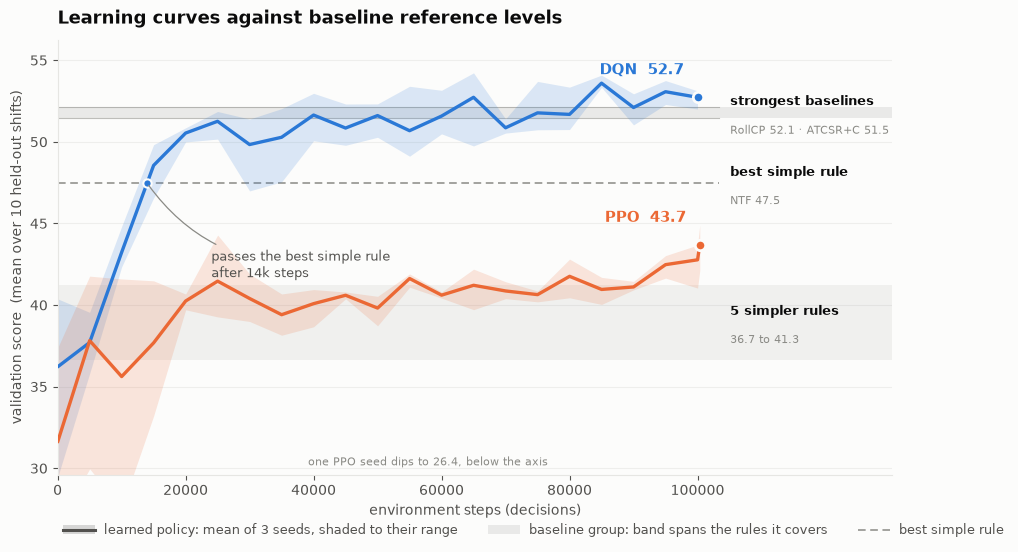


How to read it: the upper grey band is the level worth reaching - a tuned dispatch
index and a solver that re-optimises the visible queue at every decision. The dashed
line is the best of the six simple rules. If a curve is still rising at the right-hand
edge, more training will help.


In [24]:
# Plot style, shared by every figure below.
#
# Two series colours only - DQN and PPO. The baselines are drawn in grey on purpose: they are
# reference context, not competitors, and colouring ten things makes a chart unreadable. The
# blue/orange pair was checked for colour-blind separation (dE 24.7 under protanopia, 33.6 for
# normal vision), so the two learned policies stay distinguishable for every reader.

from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

BLUE, ORANGE = '#2a78d6', '#eb6834'          # DQN, PPO
INK, SECOND, MUTED = '#0b0b0b', '#52514e', '#8a8a85'
GRID, SURFACE, BAR_GREY = '#e6e6e3', '#fcfcfb', '#c9c9c4'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'font.size': 10,
    'axes.edgecolor': GRID, 'axes.labelcolor': SECOND, 'axes.titlecolor': INK,
    'xtick.color': SECOND, 'ytick.color': SECOND,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': GRID, 'grid.linewidth': 0.8,
})


def baseline_reference_scores():
    """Score every baseline on the SAME validation shifts the learning curve uses.

    This matters: the curve is measured on validation shifts, so reference lines taken from the
    test set would be an apples-to-oranges comparison. Recomputing here keeps them exact.
    """
    val = make_instances(ENV, FAMILIAR, N_VAL_SHIFTS, VAL_SEED)
    return {name: mean_metrics(evaluate(pol, val))['score']
            for name, pol in POLICIES_RULES.items()}


def plot_learning_vs_baselines(ref=None, save=True, use_cache=True):
    """Figure 1 - is it learning, and has it passed anything that matters?

    Eight dashed reference lines turned out to be six too many. Both agents clear the weak rules
    in the first few thousand steps, so those lines spend the whole chart crowding the part of
    it nobody needs to read, and their labels collide because the rules themselves score within
    a few tenths of each other. Three groups carry the entire verdict:

      * the five weaker dispatch rules, which always travel together  -> one shaded band
      * the best simple rule, because passing it is a real milestone  -> one line, kept
      * ATCSR+C and Rolling CP-SAT, the level worth reaching          -> one shaded band

    Per-seed curves become a shaded range behind each mean rather than six more lines, and the
    series are labelled where they end instead of in a legend box sitting on top of the data.
    """
    # Measuring the baselines on the validation shifts costs a couple of minutes, almost all
    # of it the rolling solver. Redrawing the figure should not pay that again, so the scores
    # are cached; pass use_cache=False after retraining or changing the environment.
    cache = RESULTS_DIR / 'validation_reference.json'
    if ref is None and use_cache and cache.exists():
        ref = json.loads(cache.read_text())
        print(f'baseline scores loaded from {cache.name} '
              f'(use_cache=False to re-measure them)')
    ref = ref if ref is not None else baseline_reference_scores()
    curves = {}
    for algo in ('ppo', 'dqn'):
        cols = {}
        for s in SEEDS:
            f = RUN_DIR / algo / f'seed{s}' / 'validation.csv'
            if f.exists():
                # keep='last' guards against logs written before the duplicate fix
                cols[s] = (pd.read_csv(f).drop_duplicates('timesteps', keep='last')
                           .set_index('timesteps')['score'])
        if cols:
            curves[algo] = pd.DataFrame(cols)
    if not curves:
        print('no validation curves found - train first')
        return

    # Group the baselines. Which rule is best is read from the data, not assumed, so the chart
    # stays correct if a re-run reorders them.
    SIMPLE = ['Random', 'FCFS', 'SPT', 'LRF', 'EDF', 'NTF']
    STRONG = ['ATCSR+C', 'RollCP']
    simple = {k: v for k, v in ref.items() if k in SIMPLE}
    strong = {k: v for k, v in ref.items() if k in STRONG}
    best_name = max(simple, key=simple.get)
    best_score = simple[best_name]
    weak = sorted(v for k, v in simple.items() if k != best_name)

    fig, ax = plt.subplots(figsize=(10.5, 6.0))
    ax.grid(axis='y', linewidth=0.8, alpha=0.6)
    ax.set_axisbelow(True)
    xmax = max(c.index.max() for c in curves.values())
    gutter = xmax * 1.03                      # where the reference labels start

    def gutter_label(y, title, detail):
        ax.annotate(title, xy=(gutter, y), xytext=(8, 3), textcoords='offset points',
                    va='bottom', ha='left', fontsize=9, color=INK, fontweight='semibold',
                    annotation_clip=False, zorder=5)
        ax.annotate(detail, xy=(gutter, y), xytext=(8, -9), textcoords='offset points',
                    va='top', ha='left', fontsize=8, color=MUTED,
                    annotation_clip=False, zorder=5)

    # --- the level worth reaching -----------------------------------------------------------
    if strong:
        lo, hi = min(strong.values()), max(strong.values())
        ax.axhspan(lo, hi, color=MUTED, alpha=0.16, linewidth=0, zorder=1)
        ax.plot([0, gutter], [hi, hi], color=MUTED, linewidth=0.8, alpha=0.55, zorder=1)
        ax.plot([0, gutter], [lo, lo], color=MUTED, linewidth=0.8, alpha=0.55, zorder=1)
        gutter_label((lo + hi) / 2, 'strongest baselines',
                     ' · '.join(f'{k} {v:.1f}' for k, v in sorted(strong.items(),
                                                                  key=lambda kv: -kv[1])))

    # --- the milestone ----------------------------------------------------------------------
    ax.plot([0, gutter], [best_score, best_score], color=MUTED, linewidth=1.1,
            linestyle=(0, (5, 3)), zorder=1)
    gutter_label(best_score, 'best simple rule', f'{best_name} {best_score:.1f}')

    # --- the rules both agents clear almost immediately --------------------------------------
    if weak:
        ax.axhspan(weak[0], weak[-1], color=MUTED, alpha=0.10, linewidth=0, zorder=1)
        gutter_label((weak[0] + weak[-1]) / 2, f'{len(weak)} simpler rules',
                     f'{weak[0]:.1f} to {weak[-1]:.1f}')

    # --- the learned policies ----------------------------------------------------------------
    ends = {}
    for algo, colour, label in (('dqn', BLUE, 'DQN'), ('ppo', ORANGE, 'PPO')):
        if algo not in curves:
            continue
        d = curves[algo]
        m = d.mean(axis=1)
        # Seed-to-seed spread as a band: the same information as six thin lines, without
        # six more things to disentangle.
        ax.fill_between(d.index, d.min(axis=1), d.max(axis=1),
                        color=colour, alpha=0.16, linewidth=0, zorder=2)
        ax.plot(m.index, m.values, color=colour, linewidth=2.4, zorder=3,
                solid_capstyle='round')
        ax.plot([m.index[-1]], [m.values[-1]], 'o', color=colour, markersize=7.5,
                markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
        ends[algo] = (m, label, colour)

    # Label each curve on itself, so no legend box has to sit on top of the data.
    for algo, (m, label, colour) in ends.items():
        ax.annotate(f'{label}  {m.values[-1]:.1f}',
                    xy=(m.index[-1], m.values[-1]), xytext=(-10, 14),
                    textcoords='offset points', ha='right', va='bottom',
                    fontsize=11, fontweight='bold', color=colour, zorder=5)

    # --- when did it pass the best simple rule? -----------------------------------------------
    if 'dqn' in ends:
        m = ends['dqn'][0]
        above = np.where(m.values >= best_score)[0]
        if len(above) and above[0] > 0:
            i = above[0]
            x0, x1 = m.index[i - 1], m.index[i]
            y0, y1 = m.values[i - 1], m.values[i]
            cross = x0 + (x1 - x0) * (best_score - y0) / (y1 - y0)   # linear between samples
            ax.plot([cross], [best_score], 'o', color=BLUE, markersize=6,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
            ax.annotate(f'passes the best simple rule\nafter {cross / 1000:.0f}k steps',
                        xy=(cross, best_score), xytext=(cross + xmax * 0.10, best_score - 4.0),
                        fontsize=9, color=SECOND, va='top', ha='left', zorder=5,
                        arrowprops=dict(arrowstyle='-', color=MUTED, linewidth=0.9,
                                        connectionstyle='arc3,rad=-0.25'))

    ax.set_xlabel('environment steps (decisions)')
    ax.set_ylabel('validation score  (mean over 10 held-out shifts)')
    ax.set_title('Learning curves against baseline reference levels',
                 fontsize=13, fontweight='bold', pad=12, loc='left')

    # A legend keyed on the marks, not the series: which curve is which is already written on
    # the curve, so repeating it here would spend the legend on something the reader has. The
    # keys are grey for the same reason - they describe shapes, not colours.
    policy_key = (Patch(facecolor=SECOND, alpha=0.22, linewidth=0),
                  Line2D([], [], color=SECOND, linewidth=2.2))
    group_key = Patch(facecolor=MUTED, alpha=0.16, linewidth=0)
    rule_key = Line2D([], [], color=MUTED, linewidth=1.1, linestyle=(0, (5, 3)))
    ax.legend([policy_key, group_key, rule_key],
              ['learned policy: mean of 3 seeds, shaded to their range',
               'baseline group: band spans the rules it covers',
               'best simple rule'],
              handler_map={tuple: HandlerTuple(ndivide=1)},   # overlay, don't tile
              loc='upper left', bbox_to_anchor=(0, -0.10), ncol=3, frameon=False,
              fontsize=9, labelcolor=SECOND, handlelength=2.6, handletextpad=0.7,
              columnspacing=2.4, borderaxespad=0)
    # The axis follows the mean curves, not the seed ranges. One PPO seed starts at an
    # untrained 26, and letting it set the floor spends a third of the canvas on a single point
    # that carries nothing. A seed that falls below the axis is named rather than quietly cropped.
    floor = min(m.values.min() for m, _, _ in ends.values()) - 2.0
    ceiling = max([curves[a].max().max() for a in ends] + [max(ref.values())]) + 2.0
    worst = min(ends, key=lambda a: curves[a].min().min())
    deepest = curves[worst].min().min()
    ax.set_ylim(floor, ceiling)
    if deepest < floor:
        # Placed right of the opening wedge, which is exactly where the clipped seed lives.
        ax.text(0.30, 0.015, f'one {ends[worst][1]} seed dips to {deepest:.1f}, below the axis',
                transform=ax.transAxes, fontsize=8, color=MUTED, va='bottom')

    # Ticks stop with the data; the space to their right is the label gutter, not more run.
    ax.set_xlim(0, xmax * 1.30)
    ax.set_xticks(np.arange(0, xmax + 1, 20_000))
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.20)        # room for the legend strip under the axes
    if save:
        fig.savefig(RESULTS_DIR / 'learning_vs_baselines.png', dpi=170,
                    bbox_inches='tight', facecolor=SURFACE)
        # Cache the reference scores. They cost a couple of minutes of solver time to measure,
        # the report quotes them, and redrawing the figure should not have to pay for them again.
        (RESULTS_DIR / 'validation_reference.json').write_text(
            json.dumps({k: float(v) for k, v in ref.items()}, indent=1))
        print('wrote', RESULTS_DIR / 'learning_vs_baselines.png')
    plt.show()
    return ref


REF_SCORES = plot_learning_vs_baselines()
print()
print('How to read it: the upper grey band is the level worth reaching - a tuned dispatch')
print('index and a solver that re-optimises the visible queue at every decision. The dashed')
print('line is the best of the six simple rules. If a curve is still rising at the right-hand')
print('edge, more training will help.')


## 17. Evaluate every policy on the test conditions

The five Part B conditions. Every policy faces the identical 100 shifts per condition, and each
learned policy is evaluated once per seed.

One naming correction carried over from the literature review: **condition 4 is not extrapolation.**
It raises the damage weight to 1.5, which is exactly the top of the training range, so it is an
in-distribution boundary test. A genuine out-of-range probe is included as condition 5, using
delta = 2.4 — the observation saturates at 2.8, so 2.4 is outside the training range while still
being distinguishable to the network.

In [25]:
@dataclass(frozen=True)
class Condition:
    name: str
    description: str
    products: tuple
    arrival_rate: float
    weights: tuple


D_HI = ENV.weight_high[2]        # top of the training range for the damage weight: 1.5
D_OOR = 2.4                      # outside the training range; the observation saturates at 2.8

CONDITIONS = [
    Condition('familiar', '1. Normal day, familiar products P1-P4', FAMILIAR, ENV.arrival_rate, EVAL_WEIGHTS),
    Condition('unseen_p5', '2a. P1-P4 plus unseen P5 (inside the training range)', FAMILIAR + ('P5',), ENV.arrival_rate, EVAL_WEIGHTS),
    Condition('unseen_p6', '2b. P1-P4 plus unseen P6 (outside the training range)', FAMILIAR + ('P6',), ENV.arrival_rate, EVAL_WEIGHTS),
    Condition('busy', '3. Busy day, arrival rate doubled', FAMILIAR, 2 * ENV.arrival_rate, EVAL_WEIGHTS),
    Condition('damage_hi', '4. Damage weight at the top of the training range (boundary, not extrapolation)', FAMILIAR, ENV.arrival_rate, EVAL_WEIGHTS[:2] + (D_HI,)),
    Condition('damage_oor', '5. Damage weight outside the training range (true extrapolation)', FAMILIAR, ENV.arrival_rate, EVAL_WEIGHTS[:2] + (D_OOR,)),
]

policies = dict(POLICIES_RULES)
for algo, loader, ext in [('ppo', load_ppo, 'zip'), ('dqn', load_dqn, 'pt')]:
    runs = [RUN_DIR / algo / f'seed{s}' / f'best_model.{ext}' for s in SEEDS]
    have = [p for p in runs if p.exists()]
    if have:
        policies[algo.upper()] = [loader(p) for p in have]
    else:
        print(f'no {algo.upper()} checkpoints found - it will be missing from the tables')

rows = []
for cond in CONDITIONS:
    cfg = replace(ENV, arrival_rate=cond.arrival_rate)
    shifts = make_instances(cfg, cond.products, N_TEST_SHIFTS, TEST_SEED)
    for name, runs in policies.items():
        for run, policy in enumerate(runs if isinstance(runs, list) else [runs]):
            for shift, metrics in enumerate(evaluate(policy, shifts, cfg, cond.weights)):
                rows.append({'condition': cond.name, 'policy': name, 'run': run, 'shift': shift,
                             **metrics, **decompose_score(metrics, cond.weights, cfg)})

df = pd.DataFrame(rows)
df.to_csv(RESULTS_DIR / 'test_shifts.csv', index=False)
if ROLLING_FALLBACKS['n']:
    print(f"WARNING: the rolling solver timed out on {ROLLING_FALLBACKS['n']} of "
          f"{ROLLING_FALLBACKS['n'] + ROLLING_FALLBACKS['solved']} decisions and fell back to the "
          f"oldest job. Raise rolling_time_limit - that baseline is not fully optimal as reported.")
else:
    print(f"rolling solver: {ROLLING_FALLBACKS['solved']:,} decisions, 0 timeouts")
print(f'{len(df)} rows -> {RESULTS_DIR / "test_shifts.csv"}')
print(df.groupby('policy')['score'].mean().round(2).sort_values(ascending=False).to_string())

2520 rows -> results\partc\test_shifts.csv
policy
DQN        23.14
ATCSR+C    22.48
RollCP     21.06
NTF        19.20
PPO         9.94
EDF         9.18
SPT         9.06
LRF         8.65
FCFS        5.77
Random      4.11


## 18. The bound on the test shifts, and the gap to it

Computed on the familiar condition only, for the first `n_bound_shifts` shifts. That is enough to
give the headline number a scale without spending hours in the solver.

The **headroom fraction** is the interpretable number to report:

> `(policy - best_rule) / (clairvoyant - best_rule)`

0% means the policy merely matched the best rule. 100% means it matched a schedule built with
perfect foreknowledge of the whole shift. Anything in between is a real, calibrated claim — and it
is the number the scheduling literature expects to see.

In [26]:
if not HAVE_ORTOOLS:
    print('ortools missing - skipping the bound')
    bound_df = pd.DataFrame()
else:
    cond = CONDITIONS[0]
    bshifts = make_instances(ENV, cond.products, N_TEST_SHIFTS, TEST_SEED)[: CFG['n_bound_shifts']]
    print(f'CP-SAT on {len(bshifts)} shifts, {CFG["bound_time_limit"]}s each, '
          f'max_jobs={CFG["bound_max_jobs"]}')
    bound_df = bound_over_shifts(bshifts, cond.weights, ENV,
                                 CFG['bound_time_limit'], CFG['bound_max_jobs'])
    bound_df.to_csv(RESULTS_DIR / 'bound.csv', index=False)
    n_opt = int((bound_df['status'] == 'OPTIMAL').sum())
    print(f'\n{n_opt}/{len(bound_df)} solved to proven optimality')
    print(bound_df[['bound', 'clairvoyant', 'seconds']].describe().loc[['mean', 'min', 'max']].round(2).to_string())

    if CFG['bound_max_jobs'] is None:
        sub = df[(df['condition'] == 'familiar') & (df['shift'].isin(bound_df['shift']))]
        per_shift = sub.groupby(['policy', 'shift'])['score'].mean().unstack('policy')
        rule_names = [c for c in per_shift.columns if c not in ('PPO', 'DQN')]
        best_rule = per_shift[rule_names].max(axis=1)
        clair = bound_df.set_index('shift')['clairvoyant'].reindex(per_shift.index)
        headroom = (clair - best_rule).replace(0, np.nan)
        frac = pd.DataFrame({p: (per_shift[p] - best_rule) / headroom
                             for p in per_shift.columns}).mean().sort_values(ascending=False)
        print('\nheadroom captured (0% = best rule, 100% = clairvoyant schedule)')
        print((frac * 100).round(1).to_string())
    else:
        print('\n(bound computed on truncated shifts, so the headroom fraction is not meaningful '
              'at this profile - it needs bound_max_jobs=None)')

CP-SAT on 10 shifts, 300.0s each, max_jobs=None
  shift   0  FEASIBLE   bound    69.93  clairvoyant    67.72  (71 jobs, 302.2s)
  shift   1  FEASIBLE   bound    71.00  clairvoyant    66.72  (72 jobs, 301.5s)
  shift   2  FEASIBLE   bound    68.48  clairvoyant    64.61  (69 jobs, 300.9s)
  shift   3  FEASIBLE   bound    88.00  clairvoyant    75.85  (89 jobs, 301.3s)
  shift   4  OPTIMAL    bound    53.76  clairvoyant    53.76  (56 jobs, 120.0s)
  shift   5  FEASIBLE   bound    89.83  clairvoyant    74.54  (90 jobs, 301.2s)
  shift   6  FEASIBLE   bound    78.66  clairvoyant    75.03  (81 jobs, 301.0s)
  shift   7  FEASIBLE   bound    65.16  clairvoyant    62.72  (66 jobs, 300.7s)
  shift   8  FEASIBLE   bound    75.83  clairvoyant  -257.77  (76 jobs, 8232.8s)
  shift   9  FEASIBLE   bound    53.27  clairvoyant    52.24  (55 jobs, 300.4s)

1/10 solved to proven optimality
      bound  clairvoyant  seconds
mean  71.39        33.54   1076.2
min   53.28      -257.77    120.0
max   89.83    

## 19. Results tables for the report

In [27]:
# Eight baselines in rising order of difficulty, then the learned policies.
ORDER = ['Random', 'FCFS', 'SPT', 'LRF', 'EDF', 'NTF', 'ATCSR+C', 'RollCP', 'PPO', 'DQN']
ORDER = [p for p in ORDER if p in set(df['policy'])]


def fmt(stats):
    return stats['mean'].map('{:.2f}'.format) + ' ± ' + stats['std'].map('{:.2f}'.format)


stats = df[df['condition'] == 'familiar'].groupby('policy')[METRICS].agg(['mean', 'std'])
familiar_table = pd.DataFrame({m: fmt(stats[m]) for m in METRICS}).reindex(ORDER).fillna('-')

stats = df.groupby(['policy', 'condition'])['score'].agg(['mean', 'std'])
score_table = fmt(stats).unstack('condition').reindex(index=ORDER,
                                                      columns=[c.name for c in CONDITIONS]).fillna('-')

parts = ['on_time_bonus', 'tardiness_cost', 'travel_cost', 'damage_cost', 'unfinished_cost', 'total']
decomp_table = df[df['condition'] == 'familiar'].groupby('policy')[parts].mean().reindex(ORDER).round(2)

display(familiar_table)
display(score_table)
print('\nwhere the score comes from (familiar condition, mean per shift):')
display(decomp_table)

,on_time,tardiness,travel,drops,scrapped,unfinished,careful,score
policy,,,,,,,,
Random,59.37 ± 5.24,147.07 ± 238.70,40.52 ± 7.86,8.70 ± 2.98,1.10 ± 0.96,1.50 ± 2.15,0.00 ± 0.00,44.36 ± 9.27
FCFS,59.53 ± 5.98,76.71 ± 136.92,39.67 ± 5.76,8.63 ± 3.03,1.13 ± 1.04,1.20 ± 1.61,0.00 ± 0.00,46.05 ± 8.44
SPT,61.60 ± 4.88,152.83 ± 248.73,40.17 ± 7.20,8.63 ± 3.02,1.13 ± 1.04,1.17 ± 1.66,0.00 ± 0.00,46.93 ± 7.00
LRF,61.27 ± 4.78,158.24 ± 250.41,40.36 ± 6.90,8.63 ± 3.02,1.13 ± 1.04,1.23 ± 1.68,0.00 ± 0.00,46.42 ± 6.74
EDF,63.13 ± 7.20,44.00 ± 120.17,40.67 ± 6.95,8.63 ± 3.03,1.13 ± 1.04,1.37 ± 1.81,0.00 ± 0.00,49.83 ± 9.68
NTF,62.33 ± 6.37,54.92 ± 96.88,29.09 ± 4.73,8.70 ± 3.04,1.13 ± 1.04,0.93 ± 1.51,0.00 ± 0.00,50.99 ± 6.68
ATCSR+C,61.80 ± 5.20,61.16 ± 103.99,26.60 ± 3.99,3.13 ± 1.89,0.37 ± 0.56,1.30 ± 1.51,50.00 ± 6.62,53.71 ± 5.72
RollCP,62.10 ± 5.72,65.14 ± 131.24,29.02 ± 3.12,3.03 ± 1.81,0.27 ± 0.52,1.50 ± 1.78,49.50 ± 8.34,53.45 ± 6.05
PPO,61.80 ± 5.64,141.26 ± 222.02,35.25 ± 5.18,8.63 ± 2.95,1.13 ± 1.03,1.17 ± 1.71,0.00 ± 0.00,48.05 ± 6.19


condition,familiar,unseen_p5,unseen_p6,busy,damage_hi,damage_oor
policy,,,,,,
Random,44.36 ± 9.27,43.41 ± 7.91,36.95 ± 15.12,-167.72 ± 60.22,37.21 ± 9.68,30.42 ± 10.84
FCFS,46.05 ± 8.44,45.37 ± 8.41,37.74 ± 15.94,-163.34 ± 59.54,38.28 ± 9.99,30.51 ± 11.98
SPT,46.93 ± 7.00,45.62 ± 6.73,41.50 ± 10.59,-150.24 ± 59.79,39.16 ± 8.56,31.39 ± 10.60
LRF,46.42 ± 6.74,45.78 ± 6.76,41.29 ± 10.51,-151.11 ± 59.51,38.65 ± 8.42,30.88 ± 10.54
EDF,49.83 ± 9.68,48.93 ± 9.89,42.31 ± 17.25,-162.30 ± 59.91,42.06 ± 10.95,34.29 ± 12.69
NTF,50.99 ± 6.68,50.73 ± 6.63,45.18 ± 9.14,-110.21 ± 59.24,43.16 ± 7.67,35.33 ± 9.39
ATCSR+C,53.71 ± 5.72,52.80 ± 7.81,47.83 ± 10.37,-111.36 ± 58.46,47.49 ± 10.06,44.42 ± 11.81
RollCP,53.45 ± 6.05,53.14 ± 7.07,46.94 ± 10.43,-116.12 ± 59.50,46.68 ± 8.82,42.26 ± 12.10
PPO,48.05 ± 6.19,47.59 ± 6.35,41.12 ± 11.10,-149.03 ± 64.10,39.99 ± 7.36,31.90 ± 9.53



where the score comes from (familiar condition, mean per shift):


,on_time_bonus,tardiness_cost,travel_cost,damage_cost,unfinished_cost,total
policy,,,,,,
Random,59.37,-2.21,-6.08,-5.22,-1.50,44.36
FCFS,59.53,-1.15,-5.95,-5.18,-1.20,46.05
SPT,61.60,-2.29,-6.03,-5.18,-1.17,46.93
LRF,61.27,-2.37,-6.05,-5.18,-1.23,46.42
EDF,63.13,-0.66,-6.10,-5.18,-1.37,49.83
NTF,62.33,-0.82,-4.36,-5.22,-0.93,50.99
ATCSR+C,61.80,-0.92,-3.99,-1.88,-1.30,53.71
RollCP,62.10,-0.98,-4.35,-1.82,-1.50,53.45
PPO,61.80,-2.12,-5.29,-5.18,-1.17,48.05


In [28]:
def markdown_lines(table):
    yield '| policy | ' + ' | '.join(str(c) for c in table.columns) + ' |'
    yield '|---' * (len(table.columns) + 1) + '|'
    for name, row in zip(table.index, table.values):
        yield '| ' + str(name) + ' | ' + ' | '.join(str(v) for v in row) + ' |'


out = RESULTS_DIR / 'partc_tables.md'
with open(out, 'w') as f:
    print(f'# Results ({PROFILE} profile)\n', file=f)
    print(f'ATCSR tuned on {N_VAL_SHIFTS} validation shifts: '
          f'K1={ATCSR_K[0]}, K2={ATCSR_K[1]}, K3={ATCSR_K[2]}\n', file=f)
    for title, table in [('Normal day, familiar products', familiar_table),
                         ('Score by test condition', score_table),
                         ('Score decomposition, familiar products', decomp_table)]:
        print('## ' + title + '\n', file=f)
        for line in markdown_lines(table):
            print(line, file=f)
        print(file=f)
    if len(bound_df):
        print('## CP-SAT clairvoyant bound\n', file=f)
        print(f'{int((bound_df["status"] == "OPTIMAL").sum())}/{len(bound_df)} shifts solved to proven '
              f'optimality; mean bound {bound_df["bound"].mean():.2f}, '
              f'mean clairvoyant schedule {bound_df["clairvoyant"].mean():.2f}. '
              'Drops are relaxed away, so this is an upper bound, not the true optimum.\n', file=f)

print(out.read_text()[:1500])

# Results (partc profile)

ATCSR tuned on 10 validation shifts: K1=8.0, K2=2.0, K3=1.0

## Normal day, familiar products

| policy | on_time | tardiness | travel | drops | scrapped | unfinished | careful | score |
|---|---|---|---|---|---|---|---|---|
| Random | 59.37 ± 5.24 | 147.07 ± 238.70 | 40.52 ± 7.86 | 8.70 ± 2.98 | 1.10 ± 0.96 | 1.50 ± 2.15 | 0.00 ± 0.00 | 44.36 ± 9.27 |
| FCFS | 59.53 ± 5.98 | 76.71 ± 136.92 | 39.67 ± 5.76 | 8.63 ± 3.03 | 1.13 ± 1.04 | 1.20 ± 1.61 | 0.00 ± 0.00 | 46.05 ± 8.44 |
| SPT | 61.60 ± 4.88 | 152.83 ± 248.73 | 40.17 ± 7.20 | 8.63 ± 3.02 | 1.13 ± 1.04 | 1.17 ± 1.66 | 0.00 ± 0.00 | 46.93 ± 7.00 |
| LRF | 61.27 ± 4.78 | 158.24 ± 250.41 | 40.36 ± 6.90 | 8.63 ± 3.02 | 1.13 ± 1.04 | 1.23 ± 1.68 | 0.00 ± 0.00 | 46.42 ± 6.74 |
| EDF | 63.13 ± 7.20 | 44.00 ± 120.17 | 40.67 ± 6.95 | 8.63 ± 3.03 | 1.13 ± 1.04 | 1.37 ± 1.81 | 0.00 ± 0.00 | 49.83 ± 9.68 |
| NTF | 62.33 ± 6.37 | 54.92 ± 96.88 | 29.09 ± 4.73 | 8.70 ± 3.04 | 1.13 ± 1.04 | 0.93 ± 1.51 | 0.00 ± 0.00 | 5

## 20. Paired statistics

Every policy faced the identical pre-drawn shifts, which makes each shift a **paired** observation.
Reporting only mean ± std throws that away: the standard deviations describe how much shifts differ
from each other, which is large, rather than how much the policies differ on the same shift, which is
the question. Two policies with heavily overlapping error bars can still differ on 95 of 100 shifts.

For each learned policy against each rule this reports, on the familiar condition:

- **mean paired difference** with a 95% confidence interval from the paired t distribution
- **Wilcoxon signed-rank p-value**, which does not assume normality
- **win rate** — the fraction of shifts the learned policy actually won

Two honest caveats to carry into the report. Pairing removes *shift* noise and **none** of the
training-seed noise, so a narrow interval here is a claim about *this trained network*, not about the
algorithm. And with many pairwise tests some correction is needed — Holm-Bonferroni over the
comparisons you actually intend to claim.

In [29]:
def paired_report(frame, condition='familiar', learned=('PPO', 'DQN')):
    sub = frame[frame['condition'] == condition]
    per = sub.groupby(['policy', 'shift'])['score'].mean().unstack('policy')
    learned = [p for p in learned if p in per.columns]
    others = [p for p in per.columns if p not in learned]

    rows = []
    for a in learned:
        for b in others:
            dif = (per[a] - per[b]).dropna()
            n = len(dif)
            if n < 3:
                continue
            mean = dif.mean()
            se = dif.std(ddof=1) / np.sqrt(n)
            if HAVE_SCIPY:
                tcrit = scipy_stats.t.ppf(0.975, n - 1)
                try:
                    pw = scipy_stats.wilcoxon(dif, zero_method='wilcox').pvalue
                except ValueError:
                    pw = np.nan
            else:
                tcrit, pw = 1.96, np.nan
            rows.append({'policy': a, 'versus': b, 'n_shifts': n,
                         'mean_diff': round(mean, 3),
                         'ci_low': round(mean - tcrit * se, 3),
                         'ci_high': round(mean + tcrit * se, 3),
                         'wilcoxon_p': pw,
                         'win_rate': round(float((dif > 0).mean()), 3),
                         'cohen_dz': round(mean / dif.std(ddof=1), 3) if dif.std(ddof=1) else np.nan})

    res = pd.DataFrame(rows)
    if len(res) and HAVE_SCIPY:
        # Holm-Bonferroni across the comparisons in this table.
        order = res['wilcoxon_p'].rank(method='first').astype(int)
        m = len(res)
        res['holm_p'] = np.minimum(1.0, res['wilcoxon_p'] * (m - order + 1))
        res['significant_holm'] = res['holm_p'] < 0.05
    return res.sort_values(['policy', 'mean_diff'], ascending=[True, False]).reset_index(drop=True)


paired = paired_report(df)
if len(paired):
    paired.to_csv(RESULTS_DIR / 'paired_stats.csv', index=False)
    display(paired)
    print('\nRead the ATCSR rows first - that is the comparison that carries weight.')
else:
    print('no learned policies to compare yet (train first)')

print('\nSeed-level spread (the honest uncertainty about the ALGORITHM, not this network):')
per_seed = df[df['condition'] == 'familiar'].groupby(['policy', 'run'])['score'].mean().unstack('run')
display(per_seed.round(2))

,policy,versus,n_shifts,mean_diff,ci_low,ci_high,wilcoxon_p,win_rate,cohen_dz,holm_p,significant_holm
0,DQN,Random,30,9.910,6.761,13.058,1.862645e-09,1.000,1.175,2.235174e-08,True
1,DQN,FCFS,30,8.221,5.609,10.834,1.862645e-09,1.000,1.175,2.607703e-08,True
2,DQN,LRF,30,7.848,5.659,10.037,3.725290e-09,0.967,1.339,4.097819e-08,True
3,DQN,SPT,30,7.338,5.197,9.479,3.725290e-09,0.967,1.280,3.725290e-08,True
4,DQN,EDF,30,4.447,1.580,7.313,1.597777e-05,0.867,0.579,1.278222e-04,True
5,DQN,NTF,30,3.281,2.480,4.081,1.862645e-09,1.000,1.531,2.421439e-08,True
6,DQN,RollCP,30,0.823,-0.233,1.878,1.909295e-01,0.600,0.291,5.727886e-01,False
7,DQN,ATCSR+C,30,0.561,-0.481,1.602,4.771065e-01,0.567,0.201,9.542130e-01,False
8,PPO,Random,30,3.684,1.449,5.918,4.968420e-05,0.833,0.615,3.477894e-04,True
9,PPO,FCFS,30,1.995,0.180,3.810,6.666471e-02,0.600,0.410,2.666588e-01,False



Read the ATCSR rows first - that is the comparison that carries weight.

Seed-level spread (the honest uncertainty about the ALGORITHM, not this network):


run,0,1,2
policy,,,
ATCSR+C,53.71,NaN,NaN
DQN,54.42,54.25,54.15
EDF,49.83,NaN,NaN
FCFS,46.05,NaN,NaN
LRF,46.42,NaN,NaN
NTF,50.99,NaN,NaN
PPO,48.54,47.58,48.02
Random,44.36,NaN,NaN
RollCP,53.45,NaN,NaN


## 21. Does the policy adapt when the penalties change?

Conditions 4 and 5 raise the damage weight through the observation only. A policy that is genuinely
reading the weights should pick careful mode more often and drop fewer items — with no retraining.

**The sharp reading:** if the score holds up but careful picks barely move, the policy did **not**
adapt, it got lucky. That distinction is the whole point of the test, so check the careful column
before writing any sentence claiming adaptation. Condition 5 is the real test, since condition 4's
weight sits exactly on the training boundary.

In [30]:
cols = ['drops', 'careful', 'score']
adapt = (df[df['condition'].isin(['familiar', 'damage_hi', 'damage_oor'])]
         .groupby(['policy', 'condition'])[cols].mean().round(2)
         .unstack('condition').reindex(ORDER))
display(adapt)

for p in [x for x in ('PPO', 'DQN') if x in set(df['policy'])]:
    try:
        c0 = adapt.loc[p, ('careful', 'familiar')]
        c1 = adapt.loc[p, ('careful', 'damage_oor')]
        d0 = adapt.loc[p, ('drops', 'familiar')]
        d1 = adapt.loc[p, ('drops', 'damage_oor')]
        verdict = 'ADAPTED' if (c1 > c0 and d1 < d0) else 'DID NOT ADAPT - do not claim it did'
        print(f'{p}: careful {c0:.1f} -> {c1:.1f}, drops {d0:.2f} -> {d1:.2f}   {verdict}')
    except KeyError:
        pass

drops                       careful                      \
condition damage_hi damage_oor familiar damage_hi damage_oor familiar   
policy                                                                  
Random         8.70       8.57     8.70      0.00       0.00     0.00   
FCFS           8.63       8.63     8.63      0.00       0.00     0.00   
SPT            8.63       8.63     8.63      0.00       0.00     0.00   
LRF            8.63       8.63     8.63      0.00       0.00     0.00   
EDF            8.63       8.63     8.63      0.00       0.00     0.00   
NTF            8.70       8.70     8.70      0.00       0.00     0.00   
ATCSR+C        2.40       2.13     3.13     63.53      68.00    50.00   
RollCP         2.40       2.10     3.03     62.97      67.20    49.50   
PPO            8.66       8.67     8.63      0.00       0.00     0.00   
DQN            5.23       6.20     4.69     28.82      19.99    34.79   

              score                      
condition damage_hi damage_oor familiar  
policy                                   
Random        37.21      30.42    44.36  
FCFS          38.28      30.51    46.05  
SPT           39.16      31.39    46.93  
LRF           38.65      30.88    46.42  
EDF           42.06      34.29    49.83  
NTF           43.16      35.33    50.99  
ATCSR+C       47.49      44.42    53.71  
RollCP        46.68      42.26    53.45  
PPO           39.99      31.90    48.05  
DQN           49.59      42.79    54.27

PPO: careful 0.0 -> 0.0, drops 8.63 -> 8.67   DID NOT ADAPT - do not claim it did
DQN: careful 34.8 -> 20.0, drops 4.69 -> 6.20   DID NOT ADAPT - do not claim it did


## Two more figures: what is real, and where it breaks

**Paired differences.** The results table gives means and standard deviations and leaves you to
guess whether a two-point gap matters. Since every policy faced identical shifts, the honest
comparison is the *per-shift difference* with its confidence interval. Anything whose interval
crosses zero is a tie, no matter how different the two means look.

**By condition.** One panel per test condition, policies in a fixed order so you can scan down
the column and see where a policy's ranking changes. Each panel keeps its own scale, because the
busy day runs to about &minus;150 and would otherwise flatten the other five to nothing.

wrote results\partc\paired_differences.png


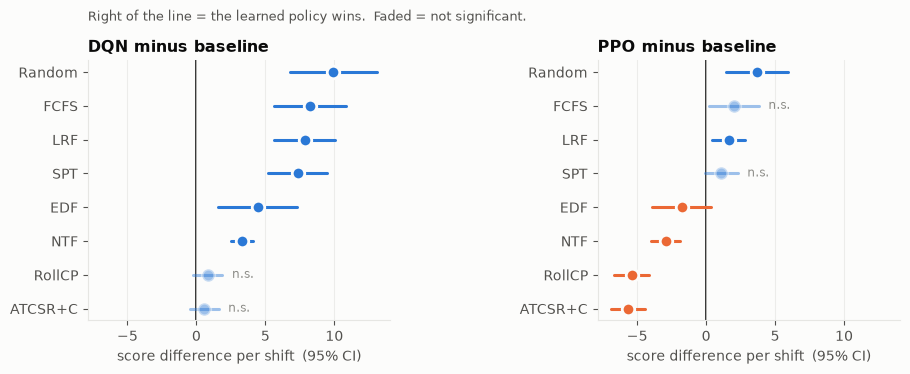

wrote results\partc\shift_differences.png


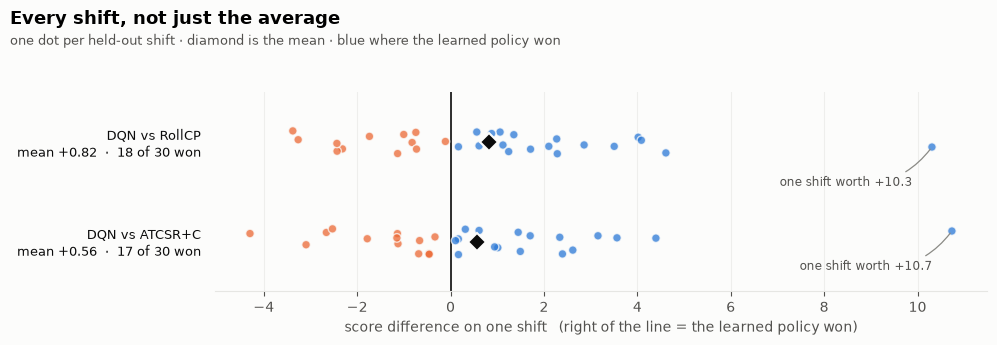

wrote results\partc\care_vs_damage.png


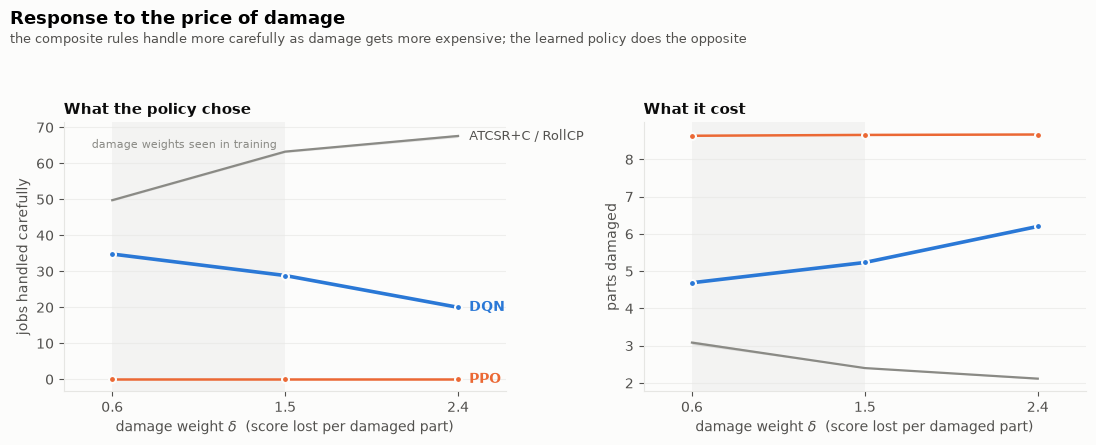

wrote results\partc\by_condition.png


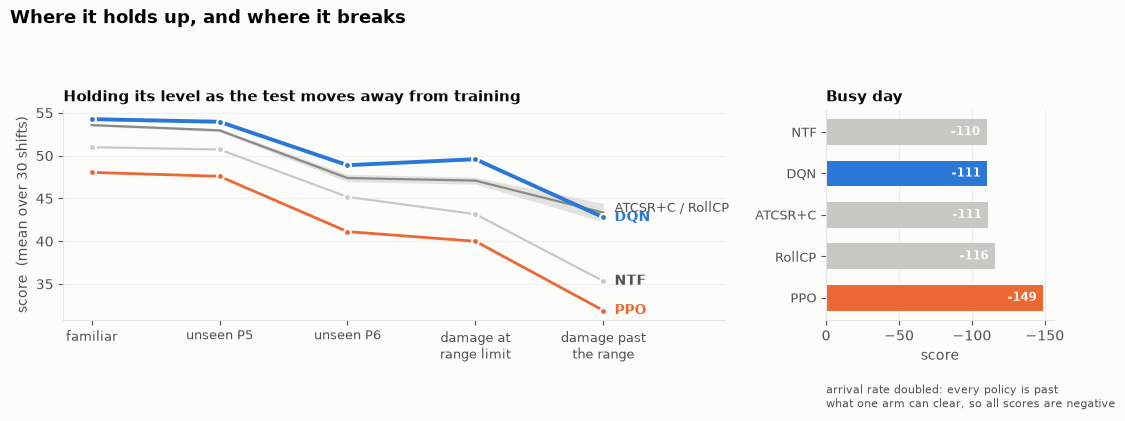

In [31]:
def results_frame(frame, name, csv):
    """The in-memory frame if there is one, else whatever the run last wrote to disk.

    Lets any figure be redrawn without re-running the evaluation that produced it, which costs
    several minutes of solver time. An explicitly passed frame always wins.
    """
    if frame is not None:
        return frame
    if name in globals():
        return globals()[name]
    path = RESULTS_DIR / csv
    if not path.exists():
        raise FileNotFoundError(
            f'`{name}` is not in memory and {path} does not exist - run the evaluation first')
    print(f'`{name}` not in memory, reading {csv}')
    return pd.read_csv(path)


def plot_paired_differences(frame=None, save=True):
    """Figure 2 - which gaps are real and which are noise.

    The results table gives two means and two standard deviations, and leaves the reader to
    guess whether a 2-point gap matters. Because every policy faced identical shifts, the honest
    comparison is the per-shift difference - which is what this plots, with its confidence
    interval. Anything whose interval crosses zero is a tie, however different the means look.
    """
    frame = results_frame(frame, 'paired', 'paired_stats.csv')
    if not len(frame):
        print('no paired statistics yet')
        return
    learned = [p for p in ('DQN', 'PPO') if p in set(frame.policy)]
    # Kept compact on purpose: this figure goes into the report at page width, and a wider
    # canvas only makes the axis text smaller once it is scaled down to fit.
    fig, axes = plt.subplots(1, len(learned), figsize=(4.6 * len(learned), 3.9), sharex=True,
                             squeeze=False)
    for ax, who in zip(axes[0], learned):
        sub = frame[frame.policy == who].sort_values('mean_diff')
        y = np.arange(len(sub))
        for yi, (_, r) in zip(y, sub.iterrows()):
            colour = BLUE if r.mean_diff > 0 else ORANGE
            sig = bool(r.get('significant_holm', False))
            ax.plot([r.ci_low, r.ci_high], [yi, yi], color=colour, linewidth=2.2,
                    alpha=1.0 if sig else 0.45, solid_capstyle='round')
            ax.plot([r.mean_diff], [yi], 'o', color=colour, markersize=9,
                    markeredgecolor=SURFACE, markeredgewidth=2, alpha=1.0 if sig else 0.45)
            if not sig:
                ax.annotate('n.s.', xy=(r.ci_high, yi), xytext=(7, 0),
                            textcoords='offset points', va='center', fontsize=8.5, color=MUTED)
        ax.axvline(0, color=INK, linewidth=1.2, zorder=0)
        ax.set_yticks(y)
        ax.set_yticklabels(sub.versus)
        ax.grid(axis='x', linewidth=0.8, alpha=0.7)
        ax.set_axisbelow(True)
        ax.set_title(f'{who} minus baseline', fontsize=11.5, fontweight='bold', loc='left')
        ax.set_xlabel('score difference per shift  (95% CI)')
    axes[0][0].text(0, 1.14, 'Right of the line = the learned policy wins.  Faded = not significant.',
                    transform=axes[0][0].transAxes, fontsize=9.5, color=SECOND, va='bottom')
    fig.tight_layout()
    if save:
        fig.savefig(RESULTS_DIR / 'paired_differences.png', dpi=170,
                    bbox_inches='tight', facecolor=SURFACE)
        print('wrote', RESULTS_DIR / 'paired_differences.png')
    plt.show()


def _spread_labels(ax, entries, x, pad_frac=0.045):
    """Draw end-of-line labels, pushed apart so two close series do not overstrike.

    Series that finish within a few tenths of each other produce labels at the same height,
    and two labels at the same height are both unreadable. Only the text moves; the line still
    ends at its true value.
    """
    lo, hi = ax.get_ylim()
    gap, placed, prev = (hi - lo) * pad_frac, [], -np.inf
    for y, text, colour, size, weight in sorted(entries, key=lambda e: e[0]):
        y_lab = max(y, prev + gap)
        placed.append(y_lab)
        prev = y_lab
        ax.annotate(text, xy=(x, y_lab), xytext=(8, 0), textcoords='offset points',
                    va='center', ha='left', fontsize=size, fontweight=weight, color=colour,
                    annotation_clip=False, zorder=5)
    return placed


def _strong_band(piv, xs, ax, label='ATCSR+C / RollCP'):
    """ATCSR+C and Rolling CP-SAT as one shaded band.

    They sit within about a point of each other on every condition and every damage weight.
    Two series that always travel together are one series; drawing both doubles the ink and
    adds nothing a reader can act on.
    """
    pair = [p for p in ('ATCSR+C', 'RollCP') if p in piv.index]
    if not pair:
        return None
    lo = piv.loc[pair].min(axis=0).values
    hi = piv.loc[pair].max(axis=0).values
    ax.fill_between(xs, lo, hi, color=MUTED, alpha=0.22, linewidth=0, zorder=2)
    ax.plot(xs, (lo + hi) / 2, color=MUTED, linewidth=1.6, zorder=2)
    return label


def plot_care_response(frame=None, save=True):
    """Figure 3 - does the policy respond to the price of damage?

    Careful handling costs time and saves parts, so the more a damaged part costs, the more of
    it you should do. The damage weight is in the observation and the agent trains across a
    range of it, so this is a question the policy is equipped to answer.

    Two panels because the behaviour and its consequence are different claims: the left panel
    is what the policy chose, the right is what it cost.
    """
    frame = results_frame(frame, 'df', 'test_shifts.csv')
    base = next(c for c in CONDITIONS if c.name == 'familiar')
    # Conditions that vary the damage weight and nothing else - same products, same load.
    sweep = sorted((c for c in CONDITIONS
                    if c.products == base.products and c.arrival_rate == base.arrival_rate),
                   key=lambda c: c.weights[2])
    if len(sweep) < 2:
        print('conditions do not sweep the damage weight - nothing to plot')
        return
    names = [c.name for c in sweep]
    xs = np.array([c.weights[2] for c in sweep])
    trained_to = ENV.weight_high[2]

    fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.4))
    for ax, field, ylab, title in (
            (axes[0], 'careful', 'jobs handled carefully',
             'What the policy chose'),
            (axes[1], 'drops', 'parts damaged',
             'What it cost')):
        piv = frame.pivot_table(index='policy', columns='condition', values=field,
                                aggfunc='mean')[names]
        ax.axvspan(xs.min(), trained_to, color=MUTED, alpha=0.07, linewidth=0, zorder=0)
        if ax is axes[0]:            # the shading is identical on both panels; name it once
            ax.annotate('damage weights seen in training', xy=(trained_to, 1.0),
                        xycoords=('data', 'axes fraction'), xytext=(-6, -12),
                        textcoords='offset points', ha='right', va='top',
                        fontsize=8, color=MUTED, zorder=3)
        _strong_band(piv, xs, ax)
        for p, colour, width in (('PPO', ORANGE, 1.8), ('DQN', BLUE, 2.6)):
            if p in piv.index:
                ax.plot(xs, piv.loc[p].values, color=colour, linewidth=width, zorder=3,
                        marker='o', markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
        ax.set_xticks(xs)
        ax.set_xlabel('damage weight $\\delta$  (score lost per damaged part)')
        ax.set_ylabel(ylab)
        ax.set_title(title, fontsize=11, fontweight='bold', loc='left')
        ax.grid(axis='y', linewidth=0.8, alpha=0.6)
        ax.set_axisbelow(True)
        ax.margins(x=0.14)

    # Label the series once, on the left panel, at the right-hand end of each line.
    piv = frame.pivot_table(index='policy', columns='condition', values='careful',
                            aggfunc='mean')[names]
    ends = [(piv.loc[p].values[-1], p, colour, 10, 'bold')
            for p, colour in (('DQN', BLUE), ('PPO', ORANGE)) if p in piv.index]
    pair = [p for p in ('ATCSR+C', 'RollCP') if p in piv.index]
    if pair:
        ends.append((piv.loc[pair].mean(axis=0).values[-1], 'ATCSR+C / RollCP',
                     SECOND, 9, 'normal'))
    _spread_labels(axes[0], ends, xs[-1])

    fig.suptitle('Response to the price of damage', fontsize=13, fontweight='bold',
                 x=0.008, ha='left', y=1.0)
    fig.text(0.008, 0.925,
             'the composite rules handle more carefully as damage gets more expensive; '
             'the learned policy does the opposite',
             fontsize=9, color=SECOND, ha='left')
    fig.tight_layout(rect=[0, 0, 1, 0.90])
    if save:
        fig.savefig(RESULTS_DIR / 'care_vs_damage.png', dpi=170, bbox_inches='tight',
                    facecolor=SURFACE)
        print('wrote', RESULTS_DIR / 'care_vs_damage.png')
    plt.show()


def plot_shift_differences(frame=None, save=True):
    """Figure 4 - is the tie a dead heat, or a few big wins?

    A confidence interval that spans zero says the difference is not distinguishable from
    noise. It does not say the two policies behave alike. Plotting every shift separates those
    two readings: a cloud centred on zero is a dead heat, a cloud of small losses with a few
    large wins is something else entirely, and only one of them is what we have.
    """
    frame = results_frame(frame, 'df', 'test_shifts.csv')
    fam = frame[frame.condition == 'familiar']
    piv = fam.pivot_table(index='shift', columns='policy', values='score')
    pairs = [('DQN', b) for b in ('ATCSR+C', 'RollCP') if b in piv.columns]
    if not pairs or 'DQN' not in piv.columns:
        print('need DQN and at least one strong baseline')
        return

    rng = np.random.default_rng(0)                    # jitter only, never the data
    fig, ax = plt.subplots(figsize=(10.0, 1.5 + 0.95 * len(pairs)))
    rows = []
    for row, (a, b) in enumerate(pairs):
        d = (piv[a] - piv[b]).dropna().values
        y = row + rng.uniform(-0.13, 0.13, len(d))
        ax.scatter(d, y, s=38, c=[BLUE if v > 0 else ORANGE for v in d],
                   alpha=0.75, edgecolors=SURFACE, linewidths=1.0, zorder=3)
        ax.plot([d.mean()], [row], marker='D', markersize=9, color=INK,
                markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=4)
        # The heading carries the mean, so nothing has to float over the cloud of dots.
        rows.append(f'{a} vs {b}\nmean {d.mean():+.2f}  \u00b7  '
                    f'{int((d > 0).sum())} of {len(d)} won')
        if d.max() > 3 * abs(d.mean()):
            best = int(np.argmax(d))
            ax.annotate(f'one shift worth {d[best]:+.1f}', xy=(d[best], y[best]),
                        xytext=(-14, -28), textcoords='offset points', ha='right',
                        fontsize=8.5, color=SECOND,
                        arrowprops=dict(arrowstyle='-', color=MUTED, linewidth=0.9,
                                        connectionstyle='arc3,rad=0.3'))

    ax.axvline(0, color=INK, linewidth=1.2, zorder=1)
    ax.set_ylim(-0.5, len(pairs) - 0.5)
    ax.set_yticks(np.arange(len(pairs)))
    ax.set_yticklabels(rows, fontsize=9.5, color=INK)
    ax.grid(axis='x', linewidth=0.8, alpha=0.6)
    ax.set_axisbelow(True)
    ax.set_xlabel('score difference on one shift   (right of the line = the learned policy won)')
    for side in ('left', 'right', 'top'):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis='y', length=0, pad=10)
    # Figure coordinates, not axes: the y labels are wide, so an axes-anchored title would
    # sit indented a fifth of the way across the page.
    fig.suptitle('Every shift, not just the average', fontsize=13, fontweight='bold',
                 x=0.008, ha='left', y=1.0)
    fig.text(0.008, 0.93, 'one dot per held-out shift \u00b7 diamond is the mean \u00b7 '
                          'blue where the learned policy won',
             fontsize=9, color=SECOND, ha='left', va='top')
    fig.tight_layout(rect=[0, 0, 1, 0.90])
    if save:
        fig.savefig(RESULTS_DIR / 'shift_differences.png', dpi=170, bbox_inches='tight',
                    facecolor=SURFACE)
        print('wrote', RESULTS_DIR / 'shift_differences.png')
    plt.show()


def plot_by_condition(frame=None, save=True):
    """Figure 5 - where it holds up, and where it breaks.

    The earlier version drew six panels of ten bars each. At page width its labels came out
    near four points, which is why it never made it into the report. The question it was asked
    to answer is narrower than sixty bars: which policies hold their level as the test moves
    away from what they were tuned on.

    So: score across the five conditions that share a scale, one line per policy, with the two
    composite baselines as a single band. The busy day sits in its own panel because at roughly
    -110 it is not on the same scale as anything else, and squeezing it in flattens the rest.
    """
    frame = results_frame(frame, 'df', 'test_shifts.csv')
    piv = frame.pivot_table(index='policy', columns='condition', values='score', aggfunc='mean')
    order = [c.name for c in CONDITIONS if c.name in piv.columns]
    normal = [c for c in order if c != 'busy']
    labels = {'familiar': 'familiar', 'unseen_p5': 'unseen P5', 'unseen_p6': 'unseen P6',
              'damage_hi': 'damage at\nrange limit', 'damage_oor': 'damage past\nthe range',
              'busy': 'busy day'}

    has_busy = 'busy' in order
    fig, axes = plt.subplots(1, 2 if has_busy else 1, squeeze=False,
                             figsize=(11.5, 4.6),
                             gridspec_kw={'width_ratios': [2.9, 1.0]} if has_busy else None)
    ax = axes[0][0]
    xs = np.arange(len(normal))
    sub = piv[normal]
    _strong_band(sub, xs, ax)
    ends = []
    for p, colour, width in (('NTF', BAR_GREY, 1.6), ('PPO', ORANGE, 2.0), ('DQN', BLUE, 2.8)):
        if p in sub.index:
            ax.plot(xs, sub.loc[p].values, color=colour, linewidth=width, zorder=3,
                    marker='o', markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
            ends.append((sub.loc[p].values[-1], p, SECOND if p == 'NTF' else colour,
                         10, 'bold'))
    pair = [p for p in ('ATCSR+C', 'RollCP') if p in sub.index]
    if pair:
        ends.append((sub.loc[pair].mean(axis=0).values[-1], 'ATCSR+C / RollCP',
                     SECOND, 9, 'normal'))
    # DQN and the band finish within a point of each other; spread the text, not the data.
    _spread_labels(ax, ends, xs[-1])
    ax.set_xticks(xs)
    ax.set_xticklabels([labels.get(c, c) for c in normal], fontsize=9)
    ax.set_ylabel('score  (mean over 30 shifts)')
    ax.set_title('Holding its level as the test moves away from training',
                 fontsize=11, fontweight='bold', loc='left')
    ax.grid(axis='y', linewidth=0.8, alpha=0.6)
    ax.set_axisbelow(True)
    ax.set_xlim(xs[0] - 0.22, xs[-1] + 0.95)   # right margin is for the end labels

    if has_busy:
        bx = axes[0][1]
        shown = [p for p in ('NTF', 'ATCSR+C', 'RollCP', 'PPO', 'DQN') if p in piv.index]
        vals = piv.loc[shown, 'busy'].sort_values()
        colours = [BLUE if n == 'DQN' else ORANGE if n == 'PPO' else BAR_GREY for n in vals.index]
        bx.barh(np.arange(len(vals)), vals.values, color=colours, height=0.62)
        bx.set_yticks(np.arange(len(vals)))
        bx.set_yticklabels(vals.index, fontsize=9)
        for i, v in enumerate(vals.values):
            bx.annotate(f'{v:.0f}', xy=(v, i), xytext=(-5, 0), textcoords='offset points',
                        ha='right', va='center', fontsize=8.5, color=SURFACE,
                        fontweight='bold')
        bx.set_title('Busy day', fontsize=11, fontweight='bold', loc='left')
        bx.set_xlabel('score')
        bx.grid(axis='x', linewidth=0.8, alpha=0.6)
        bx.set_axisbelow(True)
        bx.invert_xaxis()
        bx.text(0, -0.30, 'arrival rate doubled: every policy is past\nwhat one arm can clear, '
                          'so all scores are negative',
                transform=bx.transAxes, fontsize=8, color=SECOND, va='top')

    fig.suptitle('Where it holds up, and where it breaks', fontsize=13, fontweight='bold',
                 x=0.008, ha='left', y=1.0)
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    if save:
        fig.savefig(RESULTS_DIR / 'by_condition.png', dpi=170, bbox_inches='tight',
                    facecolor=SURFACE)
        print('wrote', RESULTS_DIR / 'by_condition.png')
    plt.show()


plot_paired_differences()
plot_shift_differences()
plot_care_response()
plot_by_condition()


## Results

- Key observations:
- Did ATCSR beat the six naive rules, and did the learned policy beat ATCSR:
- Headroom captured against the clairvoyant bound:
- Did the policy adapt to the out-of-range damage weight:
- Surprises or failure modes:
- Decision: continue, pivot, or stop:

## Still outstanding after phase 2

Ranked by value per hour, from the literature review in `reports/RL job scheduling benchmark.md`:

1. **More seeds.** Three is below the standard of about ten. Pairing shifts removes shift noise and
   none of the seed noise, so seed count is the binding constraint on any claim about the algorithm.
2. **A distance curve for generalisation** — 10 to 15 unseen products at increasing distance from the
   training box, replacing P5 and P6 as two isolated points. Evaluation-only.
3. **A control product** inside but at the edge of the training box, around (0.195, 0.88). Without
   it, a drop on P6 confounds novelty with difficulty.
4. **Per-job metrics restricted to held-out jobs**, plus the rate at which the policy selects them.
   At a 20% mix, episode-level metrics dilute the effect roughly fivefold, and a policy that finds P6
   confusing can simply decline to pick it.
5. **n-step returns in the DQN.** Rainbow's own ablation found double and dueling marginal while
   multi-step helped almost uniformly, and delayed tardiness credit is exactly what n-step attacks.
6. **A notebook-versus-package consistency test.** This notebook and `src/lvhm` are maintained by
   hand; nothing currently detects drift between them.

## Run the known-answer check

Deterministic instances, every order enumerated, so the optimum is known. Three things must agree:
brute force, our CP-SAT bound, and no policy scoring above the optimum.

In [32]:
ka = known_answer_check(n_jobs=7, n_instances=5, policies=POLICIES_RULES)
ka.to_csv(RESULTS_DIR / 'known_answer.csv', index=False)
print('\nsaved ->', RESULTS_DIR / 'known_answer.csv')

 instance  jobs  brute_force  cpsat  cpsat_matches   FCFS    SPT    LRF    EDF    NTF  Random  ATCSR+C  RollCP
        0     7       6.8275 6.8275           True 6.4825 3.8861 3.8861 6.4825 6.8275  5.1271   6.8275  6.8275
        1     7       6.8275 6.8275           True 6.4825 5.4679 5.0884 6.4825 6.8275  6.4825   6.8275  6.8275
        2     7       6.6550 6.6550           True 6.4825 5.6479 6.3100 6.1375 5.7475  4.1666   6.6550  6.6550
        3     7       6.6550 6.6550           True 6.6550 4.1943 3.8474 6.6550 3.4960  5.2720   4.5907  6.6550
        4     7       6.8275 6.8275           True 6.1375 4.3503 4.3503 6.1375 6.8275  3.8942   6.8275  6.8275

CP-SAT reproduces the brute-force optimum on all instances: True
Policies exceeding the true optimum: none (as it must be)

saved -> results\partc\known_answer.csv


## Part C report

Writes the three things the Part C brief asks for, straight into `results/partc_report.md`:

1. **Algorithms / methods chosen** &mdash; what we are comparing and why
2. **Experimental settings** &mdash; the parameters actually used, read from the live config rather
   than typed by hand, so the report cannot drift from the code
3. **Initial results** &mdash; the performance table

Every table is stamped with the profile that produced it. A `smoke` table is a code check, not a
result, and the stamp makes that impossible to misread.

In [33]:
def partc_report(path=None):
    """Write the Part C sections as Markdown, with every number read from the live run."""
    path = path or (RESULTS_DIR / 'partc_report.md')
    L = []
    W = L.append

    W('# Assignment 3, Part C — Initial Experimental Results')
    W('')
    W(f'**Project:** RL for Adaptive Job Sequencing in Low-Volume High-Mix Robotic Work Cells  ')
    W(f'**Team:** Amazing Abundance  ')
    W(f'**Generated from:** `experiments_phase2_1.ipynb`, profile `{PROFILE}`  ')
    if PROFILE != 'partc':
        warn = f'> **Note:** this run used the `{PROFILE}` profile, not `partc`.'
        if PROFILE == 'smoke':
            warn += (' Smoke numbers validate that the code runs; they are far too small to be'
                     ' reported as results. Re-run with the partc profile before submitting.')
        W(warn)
        W('')

    # A short training budget is a legitimate choice for an *initial* results report, but it has
    # to be stated or the table reads as a finished comparison. Say it automatically.
    episodes = PPO_TIMESTEPS / 77.0
    if PPO_TIMESTEPS < 150_000:
        W(f'> **Training budget.** Each learned policy saw {PPO_TIMESTEPS:,} decisions '
          f'(about {episodes:.0f} shifts of experience). This is deliberately short for an initial '
          f'report: it is enough to show the pipeline runs end to end and that learning has begun, '
          f'but **the learned policies have not converged** and may not yet beat the baselines. '
          f'The comparison below should be read as a starting point, not a result. The full study '
          f'uses {PROFILES["full"]["ppo_timesteps"]:,} steps across '
          f'{len(PROFILES["full"]["seeds"])} seeds.')
        W('')

    # ---- 1. methods ----
    W('## Algorithms / methods chosen')
    W('')
    W('The problem is formulated as a sequential decision problem: whenever the arm becomes free, '
      'choose which waiting job to serve next and how carefully to handle it. Future arrivals are '
      'unobservable, so this is a partially observable MDP.')
    W('')
    W('| Method | Type | Role |')
    W('|---|---|---|')
    W('| FCFS, SPT, EDF, NTF, LRF, Random | Single-attribute dispatch rules | Conventional baselines — what factories run today |')
    W('| ATCSR+C | Composite priority index (Vepsalainen & Morton; Lee, Bhaskaran & Pinedo), tuned on validation shifts | Combines urgency, processing time and setup cost, which no single-attribute rule does |')
    W('| Rolling CP-SAT | Constraint-programming solver, re-solved at every decision | Provably optimal on the visible queue — isolates what learning adds beyond optimisation |')
    W('| Masked PPO | On-policy deep RL (sb3-contrib MaskablePPO) | Learned policy |')
    W('| Masked double-dueling DQN | Off-policy deep RL (PyTorch) | Learned policy |')
    W('| Clairvoyant CP-SAT | Perfect-information solver | **Upper bound, not a baseline** — it sees the whole shift |')
    W('')
    W('Both learned agents share one permutation-invariant network: the same MLP embeds every '
      'waiting job, the embeddings are pooled into a queue context, and each job is scored from its '
      'own embedding plus that context (a Deep Sets architecture). Invalid actions are masked.')
    W('')

    # ---- 2. settings ----
    W('## Experimental settings')
    W('')
    W('### Problem formulation')
    W('')
    W('| Setting | Value |')
    W('|---|---|')
    W(f'| Episode length | {ENV.shift_length:.0f} s ({ENV.shift_length/60:.0f} minutes) |')
    W(f'| Arrival process | Poisson, {ENV.arrival_rate} jobs/s (≈{ENV.arrival_rate*ENV.shift_length:.0f} jobs/shift) |')
    W(f'| Input trays | {ENV.num_trays}, switching costs {ENV.travel_time} s |')
    W(f'| Observation | {LVHMSchedulingEnv(ENV).observation_space.shape[0]} values: {ENV.num_slots} job slots × {LVHMSchedulingEnv(ENV).slot_dim} features + {LVHMSchedulingEnv(ENV).global_dim} global |')
    W(f'| Action | Discrete({LVHMSchedulingEnv(ENV).action_space.n}): {ENV.num_slots} slots × (normal, careful), invalid masked |')
    W(f'| Reward | +{ENV.on_time_bonus} on time · −α/s lateness · −β/s switching · −δ/drop · −{ENV.unfinished_penalty} unfinished |')
    W(f'| Evaluation weights (α, β, δ) | {EVAL_WEIGHTS} |')
    W(f'| Products | {len(PRODUCTS)} total; {len(FAMILIAR)} for training, P5 and P6 held out |')
    W('')
    W('### Training')
    W('')
    W('| Setting | PPO | DQN |')
    W('|---|---|---|')
    W(f'| Timesteps | {PPO_TIMESTEPS:,} | {DQN_TIMESTEPS:,} |')
    W(f'| Seeds | {len(SEEDS)} ({SEEDS}) | {len(SEEDS)} ({SEEDS}) |')
    W(f'| Learning rate | {PPO_PARAMS["learning_rate"]} | {dqn_config.lr} |')
    W(f'| Discount γ | {PPO_PARAMS["gamma"]} | {dqn_config.gamma} |')
    W(f'| Batch size | {PPO_PARAMS["batch_size"]} | {dqn_config.batch_size} |')
    W(f'| Exploration | entropy coef {PPO_PARAMS["ent_coef"]} | ε {dqn_config.eps_start}→{dqn_config.eps_end} over {dqn_config.eps_fraction:.0%} |')
    W(f'| Parallel envs | 8 | {dqn_config.n_envs} |')
    W(f'| Replay buffer | — | {dqn_config.buffer_size:,} |')
    W('')
    W('### Evaluation')
    W('')
    W('| Setting | Value |')
    W('|---|---|')
    W(f'| Test shifts per condition | {N_TEST_SHIFTS} |')
    W(f'| Validation shifts (checkpoint selection) | {N_VAL_SHIFTS}, separate seed |')
    W(f'| Conditions | {len(CONDITIONS)} |')
    W('| Variance control | Common random numbers — every policy faces identical pre-drawn shifts, '
      'including the draw behind every possible drop |')
    W(f'| ATCSR tuning | grid search on validation shifts, best K = {ATCSR_K} |')
    W('')

    # ---- 3. results ----
    W('## Initial results')
    W('')
    W(f'### Normal day, familiar products (mean ± std over {N_TEST_SHIFTS} shifts)')
    W('')
    for line in markdown_lines(familiar_table):
        W(line)
    W('')
    W('### Score across all test conditions')
    W('')
    for line in markdown_lines(score_table):
        W(line)
    W('')
    W('Conditions: ' + ' · '.join(f'**{c.name}** — {c.description.split(". ", 1)[-1]}' for c in CONDITIONS))
    W('')

    if len(bound_df):
        W('### Reference ceiling')
        W('')
        opt = int((bound_df['status'] == 'OPTIMAL').sum())
        W(f'CP-SAT clairvoyant bound on {len(bound_df)} shifts, {opt} solved to proven optimality. '
          f'Mean achievable-with-hindsight score **{bound_df["clairvoyant"].mean():.2f}**, '
          f'proven ceiling **{bound_df["bound"].mean():.2f}**.')
        W('')
        W('The bound relaxes drops away, so it is an upper bound rather than the true optimum. '
          'Scores are therefore reported as *headroom captured* between the best baseline and this '
          'ceiling, not as raw values.')
        W('')

    if len(paired):
        W('### Paired comparison')
        W('')
        W(f'Because every policy faces identical shifts, each shift is a paired observation. '
          f'Reported over {N_TEST_SHIFTS} shifts on the familiar condition.')
        W('')
        keep = ['policy', 'versus', 'mean_diff', 'ci_low', 'ci_high', 'win_rate']
        sub = paired[[c for c in keep if c in paired.columns]].head(12)
        W('| ' + ' | '.join(sub.columns) + ' |')
        W('|---' * len(sub.columns) + '|')
        for _, r in sub.iterrows():
            W('| ' + ' | '.join(str(v) for v in r.values) + ' |')
        W('')

    W('### Validation of the measurement')
    W('')
    if len(ka):
        agree = bool(ka['cpsat_matches'].all()) if 'cpsat_matches' in ka else None
        W(f'On {len(ka)} deterministic instances of {int(ka["jobs"].iloc[0])} jobs — all arrivals at '
          't=0, no timing noise, no drops — every ordering was enumerated, so the optimum is known '
          'rather than estimated.')
        W('')
        W(f'- CP-SAT reproduced the brute-force optimum on every instance: **{agree}**')
        W('- No policy scored above the true optimum, as must be the case.')
        W('')
    W('')
    W(f'_Generated {time.strftime("%Y-%m-%d %H:%M")} · profile `{PROFILE}` · '
      f'{len(SEEDS)} seeds · {PPO_TIMESTEPS:,} steps · {N_TEST_SHIFTS} test shifts._')

    text = '\n'.join(L)
    path.write_text(text, encoding='utf-8')
    print(f'wrote {path}  ({len(text):,} chars)')
    return text


report = partc_report()
print()
print(report[:2000])

wrote results\partc\partc_report.md  (8,000 chars)

# Assignment 3, Part C — Initial Experimental Results

**Project:** RL for Adaptive Job Sequencing in Low-Volume High-Mix Robotic Work Cells  
**Team:** Amazing Abundance  
**Generated from:** `experiments_phase2_1.ipynb`, profile `partc`  
> **Training budget.** Each learned policy saw 100,000 decisions (about 1299 shifts of experience). This is deliberately short for an initial report: it is enough to show the pipeline runs end to end and that learning has begun, but **the learned policies have not converged** and may not yet beat the baselines. The comparison below should be read as a starting point, not a result. The full study uses 300,000 steps across 10 seeds.

## Algorithms / methods chosen

The problem is formulated as a sequential decision problem: whenever the arm becomes free, choose which waiting job to serve next and how carefully to handle it. Future arrivals are unobservable, so this is a partially observable MDP.

| M